In [8]:
# ============================================================
# Survival preparation for abstract-specific complete endpoint cohort
# Median TFx per patient + OS anchored from first cfDNA draw
#
# Key modifications:
#   1. Subtype source is controlled by RECEPTOR_SOURCE.
#
#      Options:
#        "First_Primary"
#        "Earliest_Met_Diagnosis"
#
#   2. OS time starts from first cfDNA blood draw:
#
#        Overall_Survival_days =
#            Overall_Survival_days_from_primary
#            - first_cfDNA_draw_days_from_primary
#
#   3. All available blood draws are included for patient-level
#      median TFx calculation.
#
#   4. No TFx <3% or TFx >=3% cutoff/filter is applied.
#
#   5. Abstract-specific survival cohort excludes:
#        993-24 : no follow-up after cfDNA draw for PFS
#        586-2  : missing OS information
#        999-16 : missing OS information
#
#   6. Output is saved to:
#        /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract
#
# Final saved downstream file:
#   AURORA_abstract_259_patients_median_TFx_OS_from_first_cfDNA_clean.First_Primary.csv
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================
# 1. Paths and settings
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

# ------------------------------------------------------------
# Receptor / subtype source switch
# ------------------------------------------------------------
# Options:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"

# RECEPTOR_SOURCE = "First_Primary"
RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"

VALID_RECEPTOR_SOURCES = {
    "First_Primary",
    "Earliest_Met_Diagnosis"
}

if RECEPTOR_SOURCE not in VALID_RECEPTOR_SOURCES:
    raise ValueError(
        f"Invalid RECEPTOR_SOURCE: {RECEPTOR_SOURCE}. "
        f"Allowed options are: {sorted(VALID_RECEPTOR_SOURCES)}"
    )

# ------------------------------------------------------------
# Abstract-specific complete endpoint cohort exclusions
# ------------------------------------------------------------
# Exclude patients without complete OS/PFS endpoint data:
#   993-24: no follow-up after cfDNA draw for PFS
#   586-2 : missing OS information
#   999-16: missing OS information

EXCLUDE_PATIENTS = {"993-24", "586-2", "999-16"}

# Blood-draw-level TFx source
blood_draws_xlsx = (
    BASE_DIR /
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)

blood_draws_sheet = "Blood_draws"

# Clinical source for OS, OS_event, and subtype
clinical_xlsx = BASE_DIR / "Clinical_data/AUP_ClinicalData_20260609.xlsx"

clinical_sheet = "AUP_ClinicalData_20260609.NO.DA"

# Output directory for abstract-specific complete-data cohort
out_dir = (
    BASE_DIR /
    "Survival" /
    "Abstract"
)

out_dir.mkdir(parents=True, exist_ok=True)

out_clean_csv = (
    out_dir /
    f"AURORA_abstract_259_patients_median_TFx_OS_from_first_cfDNA_clean.{RECEPTOR_SOURCE}.csv"
)

excluded_qc_csv = (
    out_dir /
    f"AURORA_abstract_excluded_patients_QC.{RECEPTOR_SOURCE}.csv"
)

print("Subtype / receptor source:")
print(RECEPTOR_SOURCE)

print("\nAbstract-specific excluded patients:")
print(sorted(EXCLUDE_PATIENTS))

print("\nBlood draws workbook:")
print(blood_draws_xlsx)

print("\nClinical workbook:")
print(clinical_xlsx)

print("\nOutput clean CSV:")
print(out_clean_csv)

print("\nExcluded-patient QC CSV:")
print(excluded_qc_csv)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_patient_id(x):
    """
    Clean patient_id so numeric IDs match across files.

    Examples:
      2        -> "2"
      2.0      -> "2"
      "2.0"    -> "2"
      "588-21" -> "588-21"
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def find_first_col(df, candidates, label):
    """
    Find the first matching column from a candidate list.
    """
    for c in candidates:
        if c in df.columns:
            return c

    raise ValueError(
        f"Could not find {label}. Tried: {candidates}\n"
        f"Available columns:\n{df.columns.tolist()}"
    )


def safe_numeric(x):
    """
    Convert to numeric. Invalid values become NaN.
    """
    return pd.to_numeric(x, errors="coerce")


def clean_receptor_status(x):
    """
    Clean ER / PR / HER2 receptor status.

    Expected values:
      Positive
      Negative
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s == "" or s in {"na", "nan", "none", "null"}:
        return pd.NA

    if s in {"positive", "pos", "+"}:
        return "Positive"

    if s in {"negative", "neg", "-"}:
        return "Negative"

    return pd.NA


def assign_subtype(er, pr, her2):
    """
    Assign molecular subtype from ER, PR, and HER2.

    Rule:
      HR+ = ER Positive OR PR Positive
      HR- = ER Negative AND PR Negative

    Output:
      HR+ Her2-
      HR+ Her2+
      HR- Her2-
      HR- Her2+
    """
    er_clean = clean_receptor_status(er)
    pr_clean = clean_receptor_status(pr)
    her2_clean = clean_receptor_status(her2)

    if pd.isna(her2_clean):
        return pd.NA

    if er_clean == "Positive" or pr_clean == "Positive":
        hr_label = "HR+"
    elif er_clean == "Negative" and pr_clean == "Negative":
        hr_label = "HR-"
    else:
        return pd.NA

    if her2_clean == "Positive":
        her2_label = "Her2+"
    elif her2_clean == "Negative":
        her2_label = "Her2-"
    else:
        return pd.NA

    return f"{hr_label} {her2_label}"


def first_nonmissing_value(x):
    """
    Return first non-missing value from a pandas Series.
    """
    x = x.dropna()
    if len(x) == 0:
        return pd.NA
    return x.iloc[0]


def code_event(x):
    """
    Code OS_event for KM analysis.

    Dead                 -> 1
    Alive with Disease   -> 0
    Lost to Follow Up    -> 0
    Lost to Follow-up    -> 0
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s == "dead":
        return 1

    if s in ["alive with disease", "lost to follow up", "lost to follow-up"]:
        return 0

    return pd.NA


def paste_unique(series, sep="; "):
    """
    Collapse unique non-missing raw labels for printed QC.
    """
    vals = []
    seen = set()

    for v in series:
        if pd.isna(v):
            continue

        s = str(v).strip()

        if s == "":
            continue

        if s not in seen:
            vals.append(s)
            seen.add(s)

    return sep.join(vals) if vals else pd.NA


def patient_sort_key(x):
    """
    Sort numeric patient IDs numerically and character IDs afterward.
    """
    try:
        return (0, float(x))
    except Exception:
        return (1, str(x))


# ============================================================
# 3. Read Blood_draws sheet
#    Calculate patient-level median TFx using all available draws
#    Identify first cfDNA blood draw day
# ============================================================

blood = pd.read_excel(
    blood_draws_xlsx,
    sheet_name=blood_draws_sheet,
    dtype=str
)

print("\n========== Blood_draws input ==========")
print("Rows:", blood.shape[0])
print("Columns:", blood.shape[1])
print(blood.columns.tolist())

blood_patient_col = find_first_col(
    blood,
    candidates=["patient_id", "Patient_ID", "patientID"],
    label="patient_id column in Blood_draws"
)

tfx_col = find_first_col(
    blood,
    candidates=[
        "Tumor_Fraction_percent_from_CNV_annotation",
        "Tumor_Fraction_percent",
        "TFx_percent",
        "Tumor_Fraction"
    ],
    label="TFx column in Blood_draws"
)

# This should be the timing of each cfDNA blood draw from primary diagnosis.
draw_day_col = find_first_col(
    blood,
    candidates=[
        "Days_From_Primary_Diagnosis",
        "Days_from_Primary_Diagnosis",
        "days_from_primary_diagnosis",
        "Blood_Draw_Days_From_Primary_Diagnosis",
        "cfDNA_Days_From_Primary_Diagnosis",
        "Days_From_Primary_Diagnosis_at_Blood_Draw"
    ],
    label="cfDNA blood draw days-from-primary-diagnosis column in Blood_draws"
)

print("\nDetected Blood_draws columns:")
print("patient_id:", blood_patient_col)
print("TFx:", tfx_col)
print("cfDNA draw day:", draw_day_col)

blood["patient_id_clean"] = blood[blood_patient_col].apply(clean_patient_id)
blood["TFx_percent"] = safe_numeric(blood[tfx_col])
blood["cfDNA_draw_days_from_primary"] = safe_numeric(blood[draw_day_col])

# If TFx appears as 0-1 fraction, convert to percent.
# Example:
#   0.03 becomes 3
# If already stored as percent, for example 3, no conversion occurs.
if blood["TFx_percent"].dropna().shape[0] > 0:
    if blood["TFx_percent"].dropna().max() <= 1:
        print("\nTFx appears to be 0-1 fraction; converting to percent.")
        blood["TFx_percent"] = blood["TFx_percent"] * 100

# Keep all patients represented in Blood_draws, even if TFx is missing.
all_tfx_patients = (
    blood.loc[blood["patient_id_clean"].notna(), ["patient_id_clean"]]
    .drop_duplicates()
    .copy()
)

# Patient-level TFx summary using all available blood draws.
# Important: no TFx cutoff/filter is applied here.
median_tfx = (
    blood.loc[blood["patient_id_clean"].notna()]
    .groupby("patient_id_clean", dropna=False)
    .agg(
        median_TFx=("TFx_percent", "median"),
        n_blood_draw_rows=("TFx_percent", "size"),
        n_nonmissing_TFx=("TFx_percent", lambda x: x.notna().sum()),
        mean_TFx=("TFx_percent", "mean"),
        min_TFx=("TFx_percent", "min"),
        max_TFx=("TFx_percent", "max"),
        n_nonmissing_cfDNA_draw_days=("cfDNA_draw_days_from_primary", lambda x: x.notna().sum()),
        first_cfDNA_draw_days_from_primary=("cfDNA_draw_days_from_primary", "min")
    )
    .reset_index()
)

median_tfx = all_tfx_patients.merge(
    median_tfx,
    on="patient_id_clean",
    how="left"
)

print("\n========== Patient-level TFx / first cfDNA draw summary ==========")
print("Patients in Blood_draws:", median_tfx.shape[0])
print("Patients with nonmissing median TFx:", median_tfx["median_TFx"].notna().sum())
print(
    "Patients with nonmissing first cfDNA draw day:",
    median_tfx["first_cfDNA_draw_days_from_primary"].notna().sum()
)

print("\nNo TFx cutoff was applied. All available draws were included for median TFx.")


# ============================================================
# 4. Read clinical sheet
# ============================================================

xls = pd.ExcelFile(clinical_xlsx)

print("\nAvailable clinical sheets:")
print(xls.sheet_names)

if clinical_sheet not in xls.sheet_names:
    possible = [s for s in xls.sheet_names if "NO.DA" in s or "ClinicalData" in s]
    print("\nCandidate sheets:", possible)
    raise ValueError(
        f"Requested sheet not found: {clinical_sheet}\n"
        f"Please update clinical_sheet using one of the available sheet names."
    )

clinical = pd.read_excel(
    clinical_xlsx,
    sheet_name=clinical_sheet,
    dtype=str
)

print("\n========== Clinical input ==========")
print("Rows:", clinical.shape[0])
print("Columns:", clinical.shape[1])
print(clinical.columns.tolist())

clinical_patient_col = find_first_col(
    clinical,
    candidates=["patient_id", "Patient_ID", "patientID"],
    label="patient_id column in clinical file"
)

category_col = find_first_col(
    clinical,
    candidates=["Category"],
    label="Category column"
)

# In your clinical file, the OS value for the row:
# Category == Overall_Survival_days
# appears to be stored under Days_From_Primary_Diagnosis.
os_time_col = find_first_col(
    clinical,
    candidates=[
        "Days_From_Primary_Diagnosis",
        "Overall_Survival_days",
        "OS_days"
    ],
    label="Overall survival days column"
)

er_col = find_first_col(
    clinical,
    candidates=["ER_Status"],
    label="ER_Status column"
)

pr_col = find_first_col(
    clinical,
    candidates=["PR_Status"],
    label="PR_Status column"
)

her2_col = find_first_col(
    clinical,
    candidates=["HER2_Status"],
    label="HER2_Status column"
)

os_event_col = find_first_col(
    clinical,
    candidates=["OS_event"],
    label="OS_event column"
)

clinical["patient_id_clean"] = clinical[clinical_patient_col].apply(clean_patient_id)

print("\nDetected clinical columns:")
print("patient_id:", clinical_patient_col)
print("Category:", category_col)
print("OS days value column:", os_time_col)
print("ER:", er_col)
print("PR:", pr_col)
print("HER2:", her2_col)
print("OS_event:", os_event_col)

# ============================================================
# 5. Derive subtype from selected receptor source
# ============================================================
# Controlled by RECEPTOR_SOURCE:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"
#
# Important fix:
#   Do not rely only on exact Category == RECEPTOR_SOURCE.
#   Some Category labels may differ slightly, especially for
#   Earliest_Met_Diagnosis.
# ============================================================

def receptor_source_mask(df, receptor_source, category_col):
    """
    Flexible receptor-source matching.

    This avoids failure when the Category label is not written
    exactly as RECEPTOR_SOURCE.
    """

    cat = df[category_col].astype(str).str.strip().str.lower()

    if receptor_source == "First_Primary":
        return (
            cat.eq("first_primary")
            | cat.eq("primary")
            | cat.str.contains("first primary", na=False)
            | cat.str.contains("first_primary", na=False)
        )

    if receptor_source == "Earliest_Met_Diagnosis":
        return (
            cat.eq("earliest_met_diagnosis")
            | cat.eq("met_diagnosis")
            | cat.eq("metastatic diagnosis")
            | cat.str.contains("earliest met", na=False)
            | cat.str.contains("earliest_met", na=False)
            | (
                cat.str.contains("met", na=False)
                & cat.str.contains("diagnosis", na=False)
            )
        )

    raise ValueError(f"Unsupported RECEPTOR_SOURCE: {receptor_source}")


# Select receptor rows using flexible source matching
receptor_rows = clinical[
    receptor_source_mask(
        clinical,
        RECEPTOR_SOURCE,
        category_col
    )
].copy()

print(f"\n========== Receptor source matching: {RECEPTOR_SOURCE} ==========")
print("Matched receptor rows:", receptor_rows.shape[0])
print("Matched unique patients:", receptor_rows["patient_id_clean"].nunique())

print("\nMatched Category values:")
if receptor_rows.shape[0] > 0:
    print(
        receptor_rows[category_col]
        .fillna("Missing")
        .value_counts(dropna=False)
        .to_string()
    )
else:
    print("No matched receptor rows found.")

    print("\nAvailable Category values containing 'met' or 'diagnosis':")
    possible_met_categories = (
        clinical[category_col]
        .dropna()
        .astype(str)
        .str.strip()
        .drop_duplicates()
    )

    possible_met_categories = possible_met_categories[
        possible_met_categories.str.lower().str.contains(
            "met|diagnosis",
            regex=True,
            na=False
        )
    ]

    print(possible_met_categories.to_string(index=False))

    raise ValueError(
        f"No receptor rows found for RECEPTOR_SOURCE = {RECEPTOR_SOURCE}. "
        "Please check the exact Category labels printed above."
    )


# Sort so that the earliest source-specific receptor row is used per patient
receptor_rows["receptor_source_day"] = safe_numeric(
    receptor_rows[os_time_col]
)

receptor_rows = receptor_rows.sort_values(
    by=[
        "patient_id_clean",
        "receptor_source_day",
        category_col
    ],
    na_position="last"
)

# Assign subtype safely.
# This avoids pandas apply(axis=1) error when the dataframe is empty.
receptor_rows["Subtype"] = [
    assign_subtype(er, pr, her2)
    for er, pr, her2 in zip(
        receptor_rows[er_col],
        receptor_rows[pr_col],
        receptor_rows[her2_col]
    )
]

subtype_patient = (
    receptor_rows.loc[receptor_rows["patient_id_clean"].notna()]
    .groupby("patient_id_clean", dropna=False)
    .agg(
        Subtype=("Subtype", first_nonmissing_value),
        n_receptor_source_rows=("Subtype", "size"),
        n_unique_Subtype=("Subtype", lambda x: x.dropna().nunique())
    )
    .reset_index()
)

print(f"\n========== {RECEPTOR_SOURCE} subtype summary ==========")
print(f"{RECEPTOR_SOURCE} matched rows:", receptor_rows.shape[0])
print(
    f"Unique patients with {RECEPTOR_SOURCE} receptor row:",
    subtype_patient["patient_id_clean"].nunique()
)
print("Patients with Subtype:", subtype_patient["Subtype"].notna().sum())

print(
    subtype_patient["Subtype"]
    .value_counts(dropna=False)
    .rename_axis("Subtype")
    .reset_index(name="n")
    .to_string(index=False)
)

# Print patients with missing subtype only
missing_subtype_detail = receptor_rows.loc[
    receptor_rows["Subtype"].isna(),
    [
        "patient_id_clean",
        category_col,
        er_col,
        pr_col,
        her2_col,
        "Subtype"
    ]
].drop_duplicates()

print(f"\n========== {RECEPTOR_SOURCE} rows with missing Subtype ==========")
print(
    "Patients with missing Subtype:",
    missing_subtype_detail["patient_id_clean"].nunique()
)

if missing_subtype_detail.shape[0] > 0:
    print(missing_subtype_detail.to_string(index=False))

# Print possible duplicate/conflicting subtype cases
subtype_conflicts = subtype_patient[
    subtype_patient["n_unique_Subtype"] > 1
].copy()

print(
    f"\nPatients with >1 Subtype within {RECEPTOR_SOURCE} rows:",
    subtype_conflicts.shape[0]
)

if subtype_conflicts.shape[0] > 0:
    print(subtype_conflicts.to_string(index=False))
    
# ============================================================
# 6. Extract original OS from primary diagnosis
# ============================================================

os_rows = clinical[
    clinical[category_col].astype(str).str.strip().eq("Overall_Survival_days")
].copy()

os_rows["Overall_Survival_days_from_primary"] = safe_numeric(os_rows[os_time_col])

print("\n========== OS rows ==========")
print("OS rows:", os_rows.shape[0])
print("Unique patients with OS rows:", os_rows["patient_id_clean"].nunique())
print(
    "Patients with numeric OS days from primary:",
    os_rows.loc[
        os_rows["Overall_Survival_days_from_primary"].notna(),
        "patient_id_clean"
    ].nunique()
)

# Collapse OS to one row per patient.
# If multiple OS rows exist for a patient, use max numeric OS days.
os_patient = (
    os_rows.loc[os_rows["patient_id_clean"].notna()]
    .groupby("patient_id_clean", dropna=False)
    .agg(
        Overall_Survival_days_from_primary=("Overall_Survival_days_from_primary", "max"),
        n_OS_rows=("Overall_Survival_days_from_primary", "size"),
        n_numeric_OS_rows=("Overall_Survival_days_from_primary", lambda x: x.notna().sum())
    )
    .reset_index()
)

print("\n========== Patient-level OS summary ==========")
print("Patients with OS row:", os_patient.shape[0])
print(
    "Patients with numeric OS days from primary:",
    os_patient["Overall_Survival_days_from_primary"].notna().sum()
)


# ============================================================
# 7. Extract OS_event and code Event
# ============================================================

print("\n========== OS_event raw values from clinical OS rows ==========")
print(os_rows[os_event_col].fillna("Missing").value_counts(dropna=False).to_string())

os_rows["Event"] = os_rows[os_event_col].apply(code_event)

print("\n========== Coded Event values ==========")
print(os_rows["Event"].fillna("Missing").value_counts(dropna=False).to_string())

event_rows = []

for pid, sub in os_rows.groupby("patient_id_clean", dropna=False):
    if pd.isna(pid):
        continue

    event_vals = sub["Event"].dropna().astype(int).tolist()

    # If any OS row says Dead, event = 1.
    # Otherwise, if alive/LTFU status exists, event = 0.
    if 1 in event_vals:
        event = 1
    elif 0 in event_vals:
        event = 0
    else:
        event = pd.NA

    event_rows.append({
        "patient_id_clean": pid,
        "Event": event,
        "OS_event_raw_all": paste_unique(sub[os_event_col]),
        "n_OS_event_rows": sub.shape[0]
    })

event_patient = pd.DataFrame(event_rows)

print("\n========== Patient-level Event summary ==========")
print("Patients with OS_event row:", event_patient.shape[0])
print(event_patient["Event"].fillna("Missing").value_counts(dropna=False).to_string())


# ============================================================
# 8. Merge TFx + first cfDNA draw + OS + Event + Subtype
# ============================================================

merged = median_tfx.merge(
    os_patient,
    on="patient_id_clean",
    how="outer",
    indicator=True
)

merged = merged.merge(
    subtype_patient[
        [
            "patient_id_clean",
            "Subtype",
            "n_receptor_source_rows",
            "n_unique_Subtype"
        ]
    ],
    on="patient_id_clean",
    how="left"
)

merged = merged.merge(
    event_patient,
    on="patient_id_clean",
    how="left"
)

print("\n========== Final merge summary ==========")
print(merged["_merge"].value_counts(dropna=False).to_string())


# ============================================================
# 9. Calculate OS anchored from first cfDNA draw
# ============================================================

merged["Overall_Survival_days"] = (
    merged["Overall_Survival_days_from_primary"]
    - merged["first_cfDNA_draw_days_from_primary"]
)

print("\n========== OS anchored from first cfDNA draw ==========")
print(
    "Patients with original OS from primary + first cfDNA draw day:",
    (
        merged["Overall_Survival_days_from_primary"].notna()
        & merged["first_cfDNA_draw_days_from_primary"].notna()
    ).sum()
)

print(
    "Patients with nonmissing OS anchored from first cfDNA draw:",
    merged["Overall_Survival_days"].notna().sum()
)

print(
    "Patients with OS anchored from first cfDNA draw < 0:",
    (merged["Overall_Survival_days"] < 0).sum()
)

print(
    "Patients with OS anchored from first cfDNA draw == 0:",
    (merged["Overall_Survival_days"] == 0).sum()
)

negative_anchor = merged.loc[
    merged["Overall_Survival_days"].notna()
    & (merged["Overall_Survival_days"] < 0),
    [
        "patient_id_clean",
        "Subtype",
        "Overall_Survival_days_from_primary",
        "first_cfDNA_draw_days_from_primary",
        "Overall_Survival_days",
        "Event"
    ]
].copy()

negative_anchor = negative_anchor.sort_values(
    by="patient_id_clean",
    key=lambda s: s.map(patient_sort_key)
)

print("\n========== Patients with negative anchored OS time ==========")
print("Number:", negative_anchor.shape[0])

if negative_anchor.shape[0] > 0:
    print(negative_anchor.to_string(index=False))


# ============================================================
# 10. Print unmatched cases
# ============================================================

tfx_only = merged.loc[
    merged["_merge"].eq("left_only"),
    [
        "patient_id_clean",
        "Subtype",
        "median_TFx",
        "n_blood_draw_rows",
        "n_nonmissing_TFx",
        "first_cfDNA_draw_days_from_primary",
        "mean_TFx",
        "min_TFx",
        "max_TFx"
    ]
].copy()

os_only = merged.loc[
    merged["_merge"].eq("right_only"),
    [
        "patient_id_clean",
        "Subtype",
        "Overall_Survival_days_from_primary",
        "n_OS_rows",
        "n_numeric_OS_rows",
        "Event",
        "OS_event_raw_all"
    ]
].copy()

tfx_only = tfx_only.sort_values(
    by="patient_id_clean",
    key=lambda s: s.map(patient_sort_key)
)

os_only = os_only.sort_values(
    by="patient_id_clean",
    key=lambda s: s.map(patient_sort_key)
)

print("\n========== Patients only in TFx table, missing OS ==========")
print("Number:", tfx_only.shape[0])

if tfx_only.shape[0] > 0:
    print(tfx_only.to_string(index=False))

print("\n========== Patients only in OS table, missing median TFx ==========")
print("Number:", os_only.shape[0])

if os_only.shape[0] > 0:
    print(os_only.to_string(index=False))


# ============================================================
# 11. Final clean downstream output before abstract exclusion
# ============================================================

merged = merged.rename(columns={"patient_id_clean": "patient_id"})

final_clean = merged[
    [
        "patient_id",
        "Subtype",
        "median_TFx",
        "n_blood_draw_rows",
        "n_nonmissing_TFx",
        "first_cfDNA_draw_days_from_primary",
        "Overall_Survival_days_from_primary",
        "Overall_Survival_days",
        "Event"
    ]
].copy()

# Add receptor source so the saved file is self-documenting.
final_clean["Receptor_source"] = RECEPTOR_SOURCE

# Reorder columns.
final_clean = final_clean[
    [
        "patient_id",
        "Receptor_source",
        "Subtype",
        "median_TFx",
        "n_blood_draw_rows",
        "n_nonmissing_TFx",
        "first_cfDNA_draw_days_from_primary",
        "Overall_Survival_days_from_primary",
        "Overall_Survival_days",
        "Event"
    ]
]

final_clean = final_clean.sort_values(
    by="patient_id",
    key=lambda s: s.map(patient_sort_key)
)

print("\n========== Final clean output before abstract exclusion ==========")
print("Rows before exclusion:", final_clean.shape[0])
print("Patients with Subtype:", final_clean["Subtype"].notna().sum())
print("Patients with median_TFx:", final_clean["median_TFx"].notna().sum())
print("Patients with first cfDNA draw day:", final_clean["first_cfDNA_draw_days_from_primary"].notna().sum())
print("Patients with OS from primary:", final_clean["Overall_Survival_days_from_primary"].notna().sum())
print("Patients with OS anchored from first cfDNA draw:", final_clean["Overall_Survival_days"].notna().sum())
print("Patients with Event:", final_clean["Event"].notna().sum())


# ============================================================
# 12. Abstract-specific exclusion
#     Keep only patients with complete OS/PFS endpoint data
# ============================================================

print("\n========== Abstract-specific exclusions ==========")
print("Patients requested for exclusion:")
print(sorted(EXCLUDE_PATIENTS))

excluded_check = final_clean[
    final_clean["patient_id"].isin(EXCLUDE_PATIENTS)
].copy()

excluded_check["exclusion_reason"] = excluded_check["patient_id"].map(
    {
        "993-24": "No follow-up after cfDNA draw for PFS calculation",
        "586-2": "Missing OS information",
        "999-16": "Missing OS information"
    }
)

print("\nExcluded patients found in final_clean:")
if excluded_check.shape[0] > 0:
    print(excluded_check.to_string(index=False))
else:
    print("None of the requested excluded patients were found in final_clean.")

excluded_check.to_csv(excluded_qc_csv, index=False)

final_clean = final_clean[
    ~final_clean["patient_id"].isin(EXCLUDE_PATIENTS)
].copy()

final_clean = final_clean.sort_values(
    by="patient_id",
    key=lambda s: s.map(patient_sort_key)
)

final_clean.to_csv(out_clean_csv, index=False)


# ============================================================
# 13. Final printed summary after abstract exclusion
# ============================================================

print("\n========== Final abstract-ready clean output summary ==========")
print("Receptor source:", RECEPTOR_SOURCE)
print("Abstract-specific excluded patients:", sorted(EXCLUDE_PATIENTS))
print("Final abstract-ready output rows:", final_clean.shape[0])

print("Patients with Subtype:", final_clean["Subtype"].notna().sum())
print("Patients with median_TFx:", final_clean["median_TFx"].notna().sum())
print("Patients with first cfDNA draw day:", final_clean["first_cfDNA_draw_days_from_primary"].notna().sum())
print("Patients with OS from primary:", final_clean["Overall_Survival_days_from_primary"].notna().sum())
print("Patients with OS anchored from first cfDNA draw:", final_clean["Overall_Survival_days"].notna().sum())
print("Patients with Event:", final_clean["Event"].notna().sum())

print(
    "\nPatients with Subtype + median_TFx + anchored OS + Event:",
    (
        final_clean["Subtype"].notna()
        & final_clean["median_TFx"].notna()
        & final_clean["Overall_Survival_days"].notna()
        & final_clean["Event"].notna()
    ).sum()
)

print(
    "\nPatients with Subtype + median_TFx + anchored OS > 0 + Event:",
    (
        final_clean["Subtype"].notna()
        & final_clean["median_TFx"].notna()
        & final_clean["Overall_Survival_days"].notna()
        & (final_clean["Overall_Survival_days"] > 0)
        & final_clean["Event"].notna()
    ).sum()
)

print("\nEvent distribution in final abstract-ready clean output:")
print(
    final_clean["Event"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\nSubtype counts in final abstract-ready clean output:")
print(
    final_clean["Subtype"]
    .value_counts(dropna=False)
    .rename_axis("Subtype")
    .reset_index(name="n")
    .to_string(index=False)
)

print("\nSaved abstract-ready downstream clean CSV:")
print(out_clean_csv)

print("\nSaved excluded-patient QC CSV:")
print(excluded_qc_csv)

print("\nPreview abstract-ready clean output:")
print(final_clean.head(20).to_string(index=False))

# Optional hard check
if final_clean.shape[0] != 259:
    print(
        "\nWARNING: Final output row count is not 259. "
        "Please check whether the starting cohort size or excluded patient IDs differ."
    )
else:
    print("\nPASS: Final abstract-ready cohort contains 259 patients.")

Subtype / receptor source:
Earliest_Met_Diagnosis

Abstract-specific excluded patients:
['586-2', '993-24', '999-16']

Blood draws workbook:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/All_cases_clinical_CNV_extraction_TSVs/All_cases_clinical_CNV_extraction.xlsx

Clinical workbook:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx

Output clean CSV:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/AURORA_abstract_259_patients_median_TFx_OS_from_first_cfDNA_clean.Earliest_Met_Diagnosis.csv

Excluded-patient QC CSV:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/AURORA_abstract_excluded_patients_QC.Earliest_Met_Diagnosis.csv

========== Blood_draws input ==========
Rows: 769
Columns: 38
['Patient_Identifier', 'patient_id', 'Site', 'mapping_status', 'Blood_Draw_Days_From_Primary_Diagnosis', 'Barcode', 'Clinical_ID', 'Clinical_ID_2', 'Active_treatment_at_draw', 'Treatment_co

Receptor source:
Earliest_Met_Diagnosis

Input file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/AURORA_abstract_259_patients_median_TFx_OS_from_first_cfDNA_clean.Earliest_Met_Diagnosis.csv

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/KM_OS_from_first_cfDNA_median_TFx_abstract_259.Earliest_Met_Diagnosis

========== Input summary ==========
Rows: 270
Columns: ['patient_id', 'Receptor_source', 'Subtype', 'median_TFx', 'n_blood_draw_rows', 'n_nonmissing_TFx', 'first_cfDNA_draw_days_from_primary', 'Overall_Survival_days_from_primary', 'Overall_Survival_days', 'Event']

========== Original subtype counts ==========
HR+ Her2-    167
HR- Her2-     54
nan           23
HR+ Her2+     20
HR- Her2+      6

========== Merged subtype counts ==========
HR+ HER2-      167
HR- HER2-       54
HR+/- HER2+     26
Missing         23

========== Survival-ready overall cohort ==========
Patients: 259
Deaths/events: 197
Censored: 62
Exclu

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:910: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


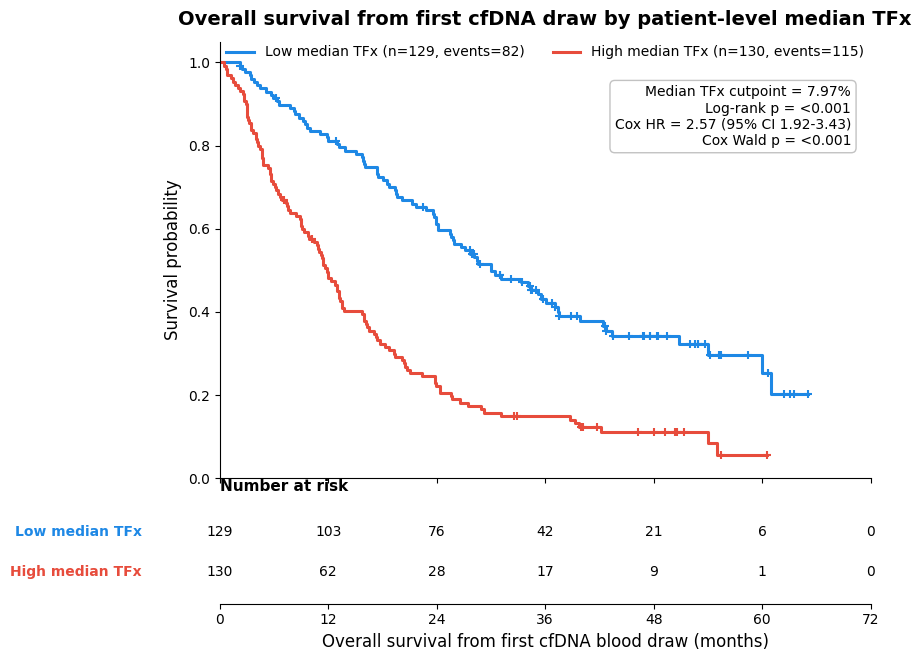


KM summary:
       Receptor_source                                                     analysis_label                  cutpoint_label median_TFx_group  n_patients_total_analysis  n_events_total_analysis  n_censored_total_analysis  n_patients_group  n_events_group  n_censored_group  median_survival_months median_survival_months_formatted  median_TFx_cutpoint  logrank_chi_square  logrank_p_value                      cox_contrast   cox_HR  cox_HR_lower_95CI  cox_HR_upper_95CI  cox_beta   cox_SE  cox_wald_p_value
Earliest_Met_Diagnosis Overall survival from first cfDNA draw by patient-level median TFx Cohort-wide median TFx cutpoint   Low median TFx                        259                      197                         62               129              82                47               29.995893                            30.00               7.9735           43.779342     3.675643e-11 High median TFx vs Low median TFx 2.568092           1.923321           3.429016  0.943163 0.147505

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:910: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


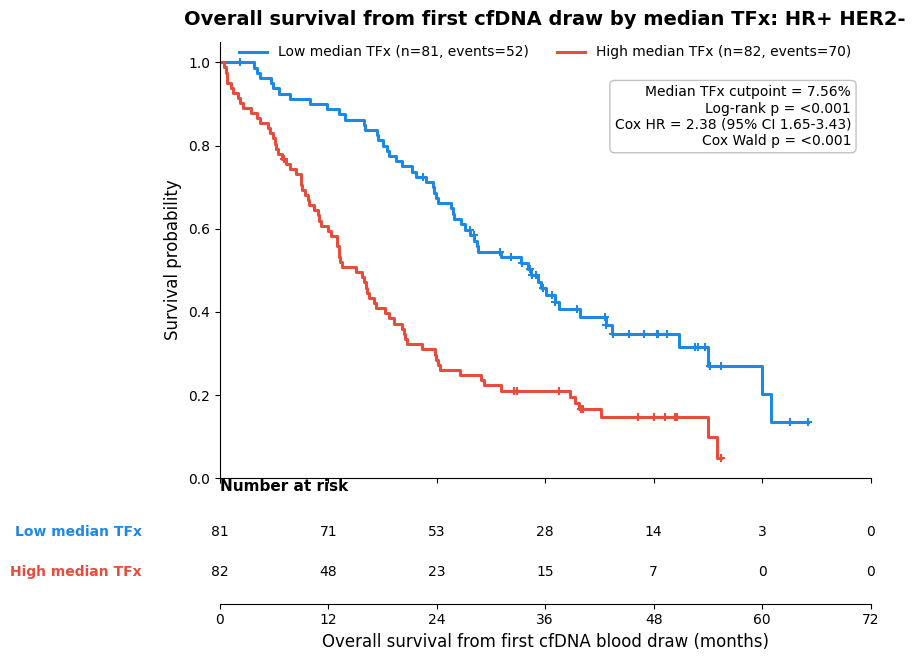


KM summary:
       Receptor_source                                                  analysis_label                                  cutpoint_label median_TFx_group  n_patients_total_analysis  n_events_total_analysis  n_censored_total_analysis  n_patients_group  n_events_group  n_censored_group  median_survival_months median_survival_months_formatted  median_TFx_cutpoint  logrank_chi_square  logrank_p_value                      cox_contrast   cox_HR  cox_HR_lower_95CI  cox_HR_upper_95CI  cox_beta   cox_SE  cox_wald_p_value
Earliest_Met_Diagnosis Overall survival from first cfDNA draw by median TFx: HR+ HER2- Subtype-specific median TFx cutpoint: HR+ HER2-   Low median TFx                        163                      122                         41                81              52                29               34.398357                            34.40                7.555           22.768642         0.000002 High median TFx vs Low median TFx 2.377803           1.647794           3

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:910: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


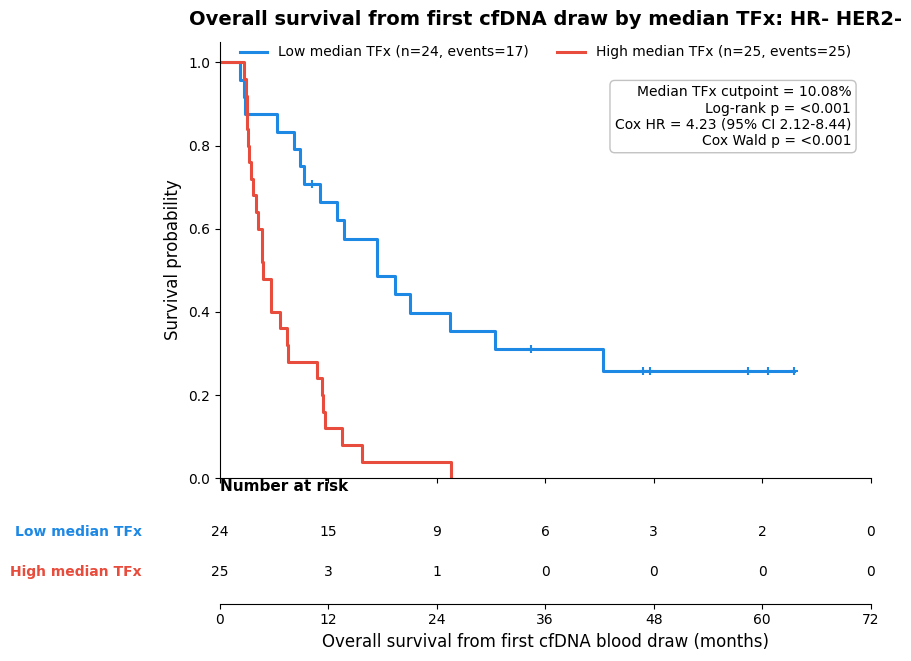


KM summary:
       Receptor_source                                                  analysis_label                                  cutpoint_label median_TFx_group  n_patients_total_analysis  n_events_total_analysis  n_censored_total_analysis  n_patients_group  n_events_group  n_censored_group  median_survival_months median_survival_months_formatted  median_TFx_cutpoint  logrank_chi_square  logrank_p_value                      cox_contrast  cox_HR  cox_HR_lower_95CI  cox_HR_upper_95CI  cox_beta   cox_SE  cox_wald_p_value
Earliest_Met_Diagnosis Overall survival from first cfDNA draw by median TFx: HR- HER2- Subtype-specific median TFx cutpoint: HR- HER2-   Low median TFx                         49                       42                          7                24              17                 7               17.412731                            17.41               10.082           18.768516         0.000015 High median TFx vs Low median TFx 4.22832           2.117785           8.4

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:910: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


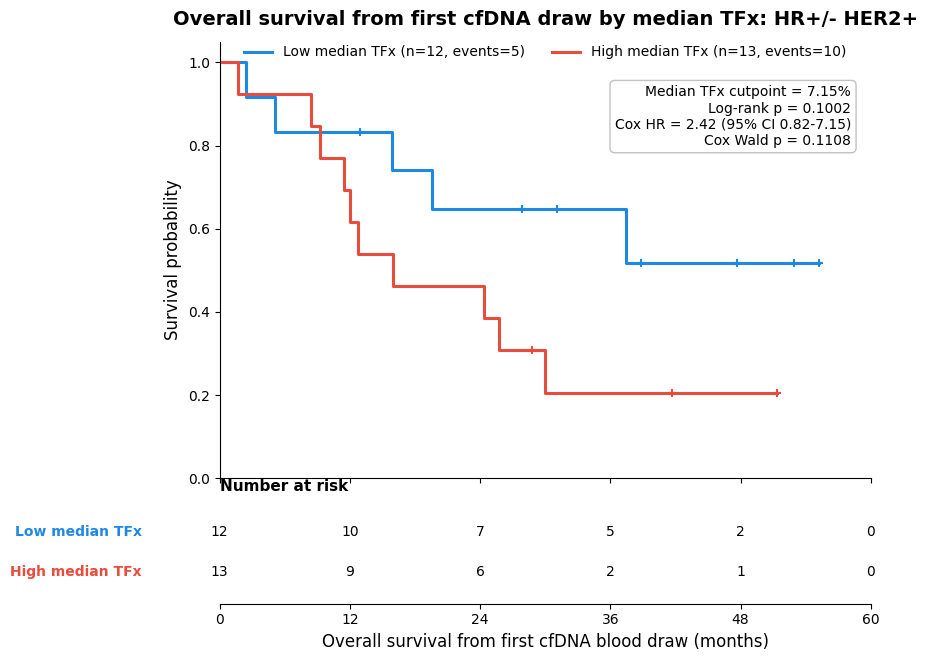


KM summary:
       Receptor_source                                                    analysis_label                                    cutpoint_label median_TFx_group  n_patients_total_analysis  n_events_total_analysis  n_censored_total_analysis  n_patients_group  n_events_group  n_censored_group  median_survival_months median_survival_months_formatted  median_TFx_cutpoint  logrank_chi_square  logrank_p_value                      cox_contrast  cox_HR  cox_HR_lower_95CI  cox_HR_upper_95CI  cox_beta   cox_SE  cox_wald_p_value
Earliest_Met_Diagnosis Overall survival from first cfDNA draw by median TFx: HR+/- HER2+ Subtype-specific median TFx cutpoint: HR+/- HER2+   Low median TFx                         25                       15                         10                12               5                 7                     NaN                      Not reached                 7.15            2.702417         0.100196 High median TFx vs Low median TFx 2.41665           0.817029      

In [9]:
# ============================================================
# Kaplan-Meier plots with risk table:
# Overall survival from first cfDNA blood draw
# by patient-level median TFx
#
# Abstract-specific 259-patient complete endpoint cohort
#
# This script generates:
#   1. Overall KM plot: all 259 patients
#   2. Subtype-wise KM plots:
#        HR+ HER2-
#        HR- HER2-
#        HR+/- HER2+
#
# HER2-positive merge:
#   HR+ HER2+ and HR- HER2+ are merged as HR+/- HER2+
#
# Input file should already contain:
#   patient_id
#   Receptor_source
#   Subtype
#   median_TFx
#   Overall_Survival_days
#   Event
#
# Important:
#   Overall_Survival_days is expected to be anchored from
#   first cfDNA blood draw:
#
#   Overall_Survival_days =
#       Overall_Survival_days_from_primary
#       - first_cfDNA_draw_days_from_primary
#
# No TFx cutoff/filter is applied here.
# Patients are split by median TFx:
#   Overall plot      : cohort-wide median TFx
#   Subtype-wise plot : subtype-specific median TFx
#
# Cox model:
#   HR = High median TFx vs Low median TFx
#
# Output:
#   /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, norm
from scipy.optimize import minimize_scalar


# ============================================================
# 1. Paths and settings
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

# ------------------------------------------------------------
# Receptor / subtype source switch
# ------------------------------------------------------------
# Options:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"

# RECEPTOR_SOURCE = "First_Primary"
RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"

VALID_RECEPTOR_SOURCES = {
    "First_Primary",
    "Earliest_Met_Diagnosis"
}

if RECEPTOR_SOURCE not in VALID_RECEPTOR_SOURCES:
    raise ValueError(
        f"Invalid RECEPTOR_SOURCE: {RECEPTOR_SOURCE}. "
        f"Allowed options are: {sorted(VALID_RECEPTOR_SOURCES)}"
    )

# ------------------------------------------------------------
# Input file from abstract-specific survival-preparation script
# ------------------------------------------------------------
input_file = (
    BASE_DIR /
    "Survival" /
    "Abstract" /
    f"AURORA_abstract_259_patients_median_TFx_OS_from_first_cfDNA_clean.{RECEPTOR_SOURCE}.csv"
)

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------
out_dir = (
    BASE_DIR /
    "Survival" /
    "Abstract" /
    f"KM_OS_from_first_cfDNA_median_TFx_abstract_259.{RECEPTOR_SOURCE}"
)

out_dir.mkdir(parents=True, exist_ok=True)

print("Receptor source:")
print(RECEPTOR_SOURCE)

print("\nInput file:")
print(input_file)

print("\nOutput directory:")
print(out_dir)


# ============================================================
# 2. Read input
# ============================================================

if not input_file.exists():
    raise FileNotFoundError(f"Input file not found:\n{input_file}")

df = pd.read_csv(input_file, dtype={"patient_id": str})

print("\n========== Input summary ==========")
print("Rows:", df.shape[0])
print("Columns:", df.columns.tolist())

required_cols = [
    "patient_id",
    "Subtype",
    "median_TFx",
    "Overall_Survival_days",
    "Event"
]

missing_cols = [
    c for c in required_cols
    if c not in df.columns
]

if len(missing_cols) > 0:
    raise ValueError(f"Missing required columns: {missing_cols}")

if "Receptor_source" not in df.columns:
    df["Receptor_source"] = RECEPTOR_SOURCE


# ============================================================
# 3. Clean input columns
# ============================================================

df["patient_id"] = df["patient_id"].astype(str).str.strip()
df["median_TFx"] = pd.to_numeric(df["median_TFx"], errors="coerce")
df["Overall_Survival_days"] = pd.to_numeric(df["Overall_Survival_days"], errors="coerce")
df["Event"] = pd.to_numeric(df["Event"], errors="coerce")

DAYS_PER_MONTH = 365.25 / 12

df["Overall_Survival_months"] = df["Overall_Survival_days"] / DAYS_PER_MONTH


# ============================================================
# 4. Subtype cleaning and HER2-positive merging
# ============================================================

def clean_subtype_label(x):
    """
    Standardize subtype labels and merge HER2-positive groups.

    Input examples:
      HR+ Her2-
      HR+ HER2-
      HR+ Her2+
      HR- Her2+
      HR- HER2-

    Output:
      HR+ HER2-
      HR- HER2-
      HR+/- HER2+
    """

    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    # Standardize HER2 capitalization
    s = s.replace("Her2", "HER2")
    s = s.replace("her2", "HER2")

    # Standardize spaces
    s = re.sub(r"\s+", " ", s).strip()

    if s == "HR+ HER2-":
        return "HR+ HER2-"

    if s == "HR- HER2-":
        return "HR- HER2-"

    if s in {"HR+ HER2+", "HR- HER2+"}:
        return "HR+/- HER2+"

    return pd.NA


df["original_receptor_subtype"] = df["Subtype"].astype(str).str.strip()
df["receptor_subtype_merged"] = df["Subtype"].apply(clean_subtype_label)

print("\n========== Original subtype counts ==========")
print(
    df["original_receptor_subtype"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\n========== Merged subtype counts ==========")
print(
    df["receptor_subtype_merged"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)


# ============================================================
# 5. Survival-ready cohort
# ============================================================

surv_all = df[
    df["median_TFx"].notna()
    & df["Overall_Survival_days"].notna()
    & (df["Overall_Survival_days"] >= 0)
    & df["Event"].notna()
    & df["Event"].isin([0, 1])
].copy()

surv_all["Event"] = surv_all["Event"].astype(int)

print("\n========== Survival-ready overall cohort ==========")
print("Patients:", surv_all.shape[0])
print("Deaths/events:", int((surv_all["Event"] == 1).sum()))
print("Censored:", int((surv_all["Event"] == 0).sum()))
print("Excluded because anchored OS < 0:", int((df["Overall_Survival_days"] < 0).sum()))

if surv_all.shape[0] == 0:
    raise RuntimeError("No survival-ready patients found.")

surv_ready_file = out_dir / "KM_survival_ready_table_abstract_259.csv"
surv_all.to_csv(surv_ready_file, index=False)


# ============================================================
# 6. Helper functions for KM, log-rank, Cox, and risk table
# ============================================================

def safe_name(x):
    """
    Convert labels into safe file names.
    """
    s = str(x)
    s = s.replace("+/-", "posneg")
    s = s.replace("+", "pos")
    s = s.replace("-", "neg")
    s = re.sub(r"\s+", "_", s)
    s = re.sub(r"[^A-Za-z0-9_]", "", s)
    return s


def km_curve(durations, events):
    """
    Manual Kaplan-Meier estimator.

    Returns:
      x, y, event_table, median_survival
    """
    data = pd.DataFrame({
        "time": pd.to_numeric(durations, errors="coerce"),
        "event": pd.to_numeric(events, errors="coerce")
    }).dropna()

    data = data.sort_values("time")

    event_times = sorted(data.loc[data["event"] == 1, "time"].unique())

    x = [0.0]
    y = [1.0]

    surv_prob = 1.0
    median_survival = np.nan
    rows = []

    for t in event_times:
        n_at_risk = int((data["time"] >= t).sum())
        n_events = int(((data["time"] == t) & (data["event"] == 1)).sum())
        n_censored = int(((data["time"] == t) & (data["event"] == 0)).sum())

        if n_at_risk > 0:
            surv_prob = surv_prob * (1 - n_events / n_at_risk)

        x.append(float(t))
        y.append(float(surv_prob))

        rows.append({
            "time": t,
            "n_at_risk": n_at_risk,
            "n_events": n_events,
            "n_censored": n_censored,
            "survival": surv_prob
        })

        if pd.isna(median_survival) and surv_prob <= 0.5:
            median_survival = t

    max_time = data["time"].max()

    if len(x) == 1 or x[-1] < max_time:
        x.append(float(max_time))
        y.append(float(surv_prob))

    return np.array(x), np.array(y), pd.DataFrame(rows), median_survival


def survival_at_censor_times(event_table, censor_times):
    """
    Survival probability at censor times, for plotting censor marks.
    """
    surv_vals = []

    for t in censor_times:
        sub = event_table[event_table["time"] <= t]

        if sub.empty:
            surv_vals.append(1.0)
        else:
            surv_vals.append(float(sub.iloc[-1]["survival"]))

    return np.array(surv_vals)


def logrank_test_two_groups(df, time_col, event_col, group_col, group_a, group_b):
    """
    Manual log-rank test for two groups.
    """
    d = df[df[group_col].isin([group_a, group_b])].copy()

    event_times = sorted(d.loc[d[event_col] == 1, time_col].dropna().unique())

    O_a = 0.0
    E_a = 0.0
    V_a = 0.0

    for t in event_times:
        n_a = ((d[group_col] == group_a) & (d[time_col] >= t)).sum()
        n_b = ((d[group_col] == group_b) & (d[time_col] >= t)).sum()
        n_total = n_a + n_b

        d_a = (
            (d[group_col] == group_a)
            & (d[time_col] == t)
            & (d[event_col] == 1)
        ).sum()

        d_b = (
            (d[group_col] == group_b)
            & (d[time_col] == t)
            & (d[event_col] == 1)
        ).sum()

        d_total = d_a + d_b

        if n_total <= 1 or d_total == 0:
            continue

        e_a = d_total * (n_a / n_total)

        v_a = (
            n_a * n_b * d_total * (n_total - d_total)
        ) / (
            (n_total ** 2) * (n_total - 1)
        )

        O_a += d_a
        E_a += e_a
        V_a += v_a

    if V_a > 0:
        chi_sq = ((O_a - E_a) ** 2) / V_a
        p_value = chi2.sf(chi_sq, df=1)
    else:
        chi_sq = np.nan
        p_value = np.nan

    return chi_sq, p_value


def coxph_binary_hr_ci(df, time_col, event_col, group_col, high_group):
    """
    Univariable Cox proportional hazards model for a binary group.

    Contrast:
      high_group vs reference group

    For this analysis:
      High median TFx vs Low median TFx

    Uses Breslow approximation for tied event times.

    Returns:
      HR, lower 95% CI, upper 95% CI, beta, SE, Wald p-value
    """
    d = df[[time_col, event_col, group_col]].dropna().copy()

    d["time"] = pd.to_numeric(d[time_col], errors="coerce")
    d["event"] = pd.to_numeric(d[event_col], errors="coerce")
    d["x"] = np.where(d[group_col] == high_group, 1.0, 0.0)

    d = d.dropna(subset=["time", "event", "x"]).copy()
    d = d[d["time"] >= 0].copy()

    if d.shape[0] == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    if d["event"].sum() == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    if d["x"].nunique() < 2:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    event_times = np.sort(d.loc[d["event"] == 1, "time"].unique())

    def neg_loglik(beta):
        beta = float(beta)
        loglik = 0.0

        for t in event_times:
            event_set = d[(d["time"] == t) & (d["event"] == 1)]
            risk_set = d[d["time"] >= t]

            d_t = event_set.shape[0]

            xb_event_sum = beta * event_set["x"].sum()
            risk_sum = np.exp(beta * risk_set["x"]).sum()

            if risk_sum <= 0:
                continue

            # Breslow partial likelihood for tied events
            loglik += xb_event_sum - d_t * np.log(risk_sum)

        return -loglik

    fit = minimize_scalar(
        neg_loglik,
        bounds=(-10, 10),
        method="bounded"
    )

    if not fit.success:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    beta_hat = float(fit.x)

    # Observed information for Cox model
    information = 0.0

    for t in event_times:
        event_set = d[(d["time"] == t) & (d["event"] == 1)]
        risk_set = d[d["time"] >= t]

        d_t = event_set.shape[0]

        weights = np.exp(beta_hat * risk_set["x"])
        s0 = weights.sum()
        s1 = (risk_set["x"] * weights).sum()
        s2 = ((risk_set["x"] ** 2) * weights).sum()

        if s0 <= 0:
            continue

        information += d_t * ((s2 / s0) - ((s1 / s0) ** 2))

    if information <= 0:
        return np.nan, np.nan, np.nan, beta_hat, np.nan, np.nan

    se_beta = np.sqrt(1 / information)

    hr = np.exp(beta_hat)
    ci_low = np.exp(beta_hat - 1.96 * se_beta)
    ci_high = np.exp(beta_hat + 1.96 * se_beta)

    z = beta_hat / se_beta
    wald_p = 2 * norm.sf(abs(z))

    return hr, ci_low, ci_high, beta_hat, se_beta, wald_p


def fmt_p(p):
    """
    Format p-value for plot label.
    """
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return "<0.001"
    return f"{p:.4f}"


def fmt_hr_ci(hr, ci_low, ci_high):
    """
    Format HR and 95% CI for plot label.
    """
    if pd.isna(hr) or pd.isna(ci_low) or pd.isna(ci_high):
        return "HR = NA"

    return f"HR = {hr:.2f} (95% CI {ci_low:.2f}-{ci_high:.2f})"


def fmt_median(x):
    """
    Format median survival.
    """
    if pd.isna(x):
        return "Not reached"
    return f"{x:.2f}"


def make_time_ticks(max_months):
    """
    Create clean x-axis and risk-table time points.
    Uses wider spacing if follow-up is long.
    """
    if pd.isna(max_months) or max_months <= 0:
        return np.array([0, 12, 24, 36, 48, 60])

    upper = int(np.ceil(max_months / 12.0) * 12)

    if upper < 60:
        upper = 60

    if upper <= 72:
        step = 12
    elif upper <= 144:
        step = 24
    else:
        step = 36

    return np.arange(0, upper + step, step)


def number_at_risk(df, time_col, group_col, group_order, time_points):
    """
    Number at risk at each time point.

    Definition:
      At risk at time t = patients with observed time >= t.
    """
    rows = []

    for group in group_order:
        sub = df[df[group_col] == group].copy()

        row = {"group": group}

        for t in time_points:
            row[t] = int((sub[time_col] >= t).sum())

        rows.append(row)

    return pd.DataFrame(rows)


# ============================================================
# 7. Function to run KM analysis and save plot
# ============================================================

def run_km_analysis(
    data,
    analysis_label,
    output_prefix,
    cutpoint_label
):
    """
    Run KM, log-rank, Cox HR, risk table, and plot.

    Parameters
    ----------
    data : pandas DataFrame
        Survival-ready data for one analysis.
    analysis_label : str
        Plot title label.
    output_prefix : str
        File prefix for outputs.
    cutpoint_label : str
        Label describing whether cutpoint is cohort-wide or subtype-specific.
    """

    data = data.copy()

    print("\n============================================================")
    print("Running KM analysis:", analysis_label)
    print("============================================================")

    n_patients = data.shape[0]
    n_events = int((data["Event"] == 1).sum())
    n_censored = int((data["Event"] == 0).sum())

    print("Patients:", n_patients)
    print("Deaths/events:", n_events)
    print("Censored:", n_censored)

    if n_patients < 6:
        print("Skipping: too few patients.")
        return None

    if n_events < 2:
        print("Skipping: too few events.")
        return None

    # --------------------------------------------------------
    # Median TFx cutpoint within this analysis dataset
    # --------------------------------------------------------
    median_cut = data["median_TFx"].median()

    data["median_TFx_group"] = np.where(
        data["median_TFx"] >= median_cut,
        "High median TFx",
        "Low median TFx"
    )

    group_counts = data["median_TFx_group"].value_counts()

    print("\nMedian TFx grouping:")
    print(f"{cutpoint_label}: {median_cut:.4f}%")
    print(group_counts.to_string())

    if data["median_TFx_group"].nunique() < 2:
        print("Skipping: only one TFx group present.")
        return None

    group_order = [
        "Low median TFx",
        "High median TFx"
    ]

    group_colors = {
        "Low median TFx": "#1E88E5",
        "High median TFx": "#E74C3C"
    }

    # --------------------------------------------------------
    # Log-rank test
    # --------------------------------------------------------
    chi_sq, logrank_p = logrank_test_two_groups(
        data,
        time_col="Overall_Survival_months",
        event_col="Event",
        group_col="median_TFx_group",
        group_a="Low median TFx",
        group_b="High median TFx"
    )

    print("\nLog-rank test:")
    print(f"Chi-square: {chi_sq}")
    print(f"p-value: {logrank_p}")

    # --------------------------------------------------------
    # Cox model
    # --------------------------------------------------------
    cox_hr, cox_ci_low, cox_ci_high, cox_beta, cox_se, cox_p = coxph_binary_hr_ci(
        data,
        time_col="Overall_Survival_months",
        event_col="Event",
        group_col="median_TFx_group",
        high_group="High median TFx"
    )

    print("\nCox proportional hazards model:")
    print("Contrast: High median TFx vs Low median TFx")
    print(f"HR: {cox_hr}")
    print(f"95% CI lower: {cox_ci_low}")
    print(f"95% CI upper: {cox_ci_high}")
    print(f"beta: {cox_beta}")
    print(f"SE: {cox_se}")
    print(f"Wald p-value: {cox_p}")

    # --------------------------------------------------------
    # Save survival-ready subset
    # --------------------------------------------------------
    subset_file = out_dir / f"{output_prefix}_survival_ready_table.csv"
    data.to_csv(subset_file, index=False)

    # --------------------------------------------------------
    # Risk table
    # --------------------------------------------------------
    max_months = data["Overall_Survival_months"].max()
    time_ticks = make_time_ticks(max_months)

    risk_table = number_at_risk(
        data,
        time_col="Overall_Survival_months",
        group_col="median_TFx_group",
        group_order=group_order,
        time_points=time_ticks
    )

    risk_table_file = out_dir / f"{output_prefix}_number_at_risk_table.csv"
    risk_table.to_csv(risk_table_file, index=False)

    # --------------------------------------------------------
    # Plot KM curve with risk table
    # --------------------------------------------------------
    km_summary_rows = []

    fig = plt.figure(figsize=(8.4, 7.3))

    gs = fig.add_gridspec(
        nrows=2,
        ncols=1,
        height_ratios=[4.2, 1.0],
        hspace=0.08
    )

    ax = fig.add_subplot(gs[0])
    ax_risk = fig.add_subplot(gs[1], sharex=ax)

    for group in group_order:
        sub = data[data["median_TFx_group"] == group].copy()

        x, y, event_table, median_surv = km_curve(
            sub["Overall_Survival_months"],
            sub["Event"]
        )

        group_n = sub.shape[0]
        group_events = int((sub["Event"] == 1).sum())
        group_censored = int((sub["Event"] == 0).sum())

        ax.step(
            x,
            y,
            where="post",
            color=group_colors[group],
            linewidth=2.2,
            label=f"{group} (n={group_n}, events={group_events})"
        )

        # Censor marks
        censor_times = (
            sub.loc[sub["Event"] == 0, "Overall_Survival_months"]
            .dropna()
            .values
        )

        censor_y = survival_at_censor_times(event_table, censor_times)

        if len(censor_times) > 0:
            ax.scatter(
                censor_times,
                censor_y,
                marker="+",
                s=38,
                linewidths=1.5,
                color=group_colors[group]
            )

        km_summary_rows.append({
            "Receptor_source": RECEPTOR_SOURCE,
            "analysis_label": analysis_label,
            "cutpoint_label": cutpoint_label,
            "median_TFx_group": group,
            "n_patients_total_analysis": n_patients,
            "n_events_total_analysis": n_events,
            "n_censored_total_analysis": n_censored,
            "n_patients_group": group_n,
            "n_events_group": group_events,
            "n_censored_group": group_censored,
            "median_survival_months": median_surv,
            "median_survival_months_formatted": fmt_median(median_surv),
            "median_TFx_cutpoint": median_cut,
            "logrank_chi_square": chi_sq,
            "logrank_p_value": logrank_p,
            "cox_contrast": "High median TFx vs Low median TFx",
            "cox_HR": cox_hr,
            "cox_HR_lower_95CI": cox_ci_low,
            "cox_HR_upper_95CI": cox_ci_high,
            "cox_beta": cox_beta,
            "cox_SE": cox_se,
            "cox_wald_p_value": cox_p
        })

    # --------------------------------------------------------
    # Main KM plot styling
    # --------------------------------------------------------
    ax.set_title(
        analysis_label,
        fontsize=14,
        fontweight="bold",
        pad=12
    )

    ax.set_ylabel("Survival probability", fontsize=12)
    ax.set_ylim(0, 1.05)

    ax.set_xlim(time_ticks.min(), time_ticks.max())
    ax.set_xticks(time_ticks)

    plt.setp(ax.get_xticklabels(), visible=False)

    ax.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=2,
        frameon=False,
        fontsize=10
    )

    ax.text(
        0.97,
        0.90,
        (
            f"Median TFx cutpoint = {median_cut:.2f}%\n"
            f"Log-rank p = {fmt_p(logrank_p)}\n"
            f"Cox {fmt_hr_ci(cox_hr, cox_ci_low, cox_ci_high)}\n"
            f"Cox Wald p = {fmt_p(cox_p)}"
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="0.75",
            alpha=0.95
        )
    )

    # --------------------------------------------------------
    # Risk table styling
    # --------------------------------------------------------
    ax_risk.set_ylim(-0.8, len(group_order) - 0.2)
    ax_risk.set_xlim(time_ticks.min(), time_ticks.max())
    ax_risk.set_xticks(time_ticks)

    ax_risk.set_xlabel(
        "Overall survival from first cfDNA blood draw (months)",
        fontsize=12
    )

    ax_risk.set_yticks([])

    ax_risk.grid(False)

    for spine in ["top", "right", "left"]:
        ax_risk.spines[spine].set_visible(False)

    ax_risk.spines["bottom"].set_visible(True)

    ax_risk.text(
        time_ticks.min(),
        len(group_order) - 0.05,
        "Number at risk",
        ha="left",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

    for row_index, group in enumerate(group_order):
        y_pos = len(group_order) - 1 - row_index

        label_x = time_ticks.min() - (time_ticks.max() - time_ticks.min()) * 0.12

        ax_risk.text(
            label_x,
            y_pos,
            group,
            ha="right",
            va="center",
            fontsize=10,
            color=group_colors[group],
            fontweight="bold",
            clip_on=False
        )

        sub = data[data["median_TFx_group"] == group].copy()

        for t in time_ticks:
            n_risk = int((sub["Overall_Survival_months"] >= t).sum())

            ax_risk.text(
                t,
                y_pos,
                str(n_risk),
                ha="center",
                va="center",
                fontsize=10,
                color="black"
            )

    plt.tight_layout()

    km_png = out_dir / f"{output_prefix}_KM_with_risk_table_HR_CI.png"
    km_pdf = out_dir / f"{output_prefix}_KM_with_risk_table_HR_CI.pdf"

    plt.savefig(km_png, dpi=300, bbox_inches="tight")
    plt.savefig(km_pdf, bbox_inches="tight")
    plt.show()
    plt.close()

    # --------------------------------------------------------
    # Save KM summary
    # --------------------------------------------------------
    km_summary = pd.DataFrame(km_summary_rows)

    km_summary_file = out_dir / f"{output_prefix}_KM_summary_HR_CI.csv"
    km_summary.to_csv(km_summary_file, index=False)

    print("\nKM summary:")
    print(km_summary.to_string(index=False))

    print("\nNumber at risk table:")
    print(risk_table.to_string(index=False))

    print("\nSaved files:")
    print(km_png)
    print(km_pdf)
    print(km_summary_file)
    print(risk_table_file)
    print(subset_file)

    return km_summary


# ============================================================
# 8. Overall KM plot: all 259 patients
# ============================================================

all_summaries = []

overall_summary = run_km_analysis(
    data=surv_all,
    analysis_label="Overall survival from first cfDNA draw by patient-level median TFx",
    output_prefix="Overall_abstract_259_OS_from_first_cfDNA_median_TFx",
    cutpoint_label="Cohort-wide median TFx cutpoint"
)

if overall_summary is not None:
    all_summaries.append(overall_summary)


# ============================================================
# 9. Subtype-wise KM plots
#    HR+ HER2-
#    HR- HER2-
#    HR+/- HER2+
# ============================================================

subtype_order = [
    "HR+ HER2-",
    "HR- HER2-",
    "HR+/- HER2+"
]

surv_subtype_ready = surv_all[
    surv_all["receptor_subtype_merged"].notna()
].copy()

subtype_ready_file = out_dir / "Subtype_HER2pos_combined_survival_ready_table.csv"
surv_subtype_ready.to_csv(subtype_ready_file, index=False)

print("\n========== Subtype-ready cohort ==========")
print("Patients with usable merged subtype:", surv_subtype_ready.shape[0])

print("\nSubtype counts:")
print(
    surv_subtype_ready["receptor_subtype_merged"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nSubtype events:")
print(
    pd.crosstab(
        surv_subtype_ready["receptor_subtype_merged"],
        surv_subtype_ready["Event"]
    ).to_string()
)

for subtype in subtype_order:

    sub_df = surv_subtype_ready[
        surv_subtype_ready["receptor_subtype_merged"] == subtype
    ].copy()

    output_prefix = (
        "Subtype_"
        + safe_name(subtype)
        + "_abstract_259_OS_from_first_cfDNA_median_TFx"
    )

    subtype_summary = run_km_analysis(
        data=sub_df,
        analysis_label=f"Overall survival from first cfDNA draw by median TFx: {subtype}",
        output_prefix=output_prefix,
        cutpoint_label=f"Subtype-specific median TFx cutpoint: {subtype}"
    )

    if subtype_summary is not None:
        all_summaries.append(subtype_summary)


# ============================================================
# 10. Save combined KM summary
# ============================================================

if len(all_summaries) > 0:
    combined_summary = pd.concat(all_summaries, ignore_index=True)

    combined_summary_file = out_dir / "Combined_overall_and_subtype_KM_summary_abstract_259_HR_CI.csv"
    combined_summary.to_csv(combined_summary_file, index=False)

    print("\n============================================================")
    print("Saved combined overall + subtype KM summary:")
    print(combined_summary_file)
    print("============================================================")

    print(combined_summary.to_string(index=False))

else:
    print("\nNo KM summaries were generated.")


# ============================================================
# 11. Final output reminder
# ============================================================

print("\n============================================================")
print("Analysis complete.")
print("Main output directory:")
print(out_dir)
print("============================================================")

Clinical file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx

Blood-draw file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/All_cases_clinical_CNV_extraction_TSVs/All_cases_clinical_CNV_extraction.xlsx

Receptor source:
Earliest_Met_Diagnosis

Abstract-specific excluded patients:
['586-2', '993-24', '999-16']

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis

========== Blood_draws input ==========
Rows: 769
Columns: 38
['Patient_Identifier', 'patient_id', 'Site', 'mapping_status', 'Blood_Draw_Days_From_Primary_Diagnosis', 'Barcode', 'Clinical_ID', 'Clinical_ID_2', 'Active_treatment_at_draw', 'Treatment_context_at_draw', 'Most_recent_treatment_before_draw', 'Most_recent_treatment_start_day', 'Most_recent_treatment_end_day', 'Most_recent_treatment_response_recorded', 'Most_recent_treatment_progression_rec

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:1573: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


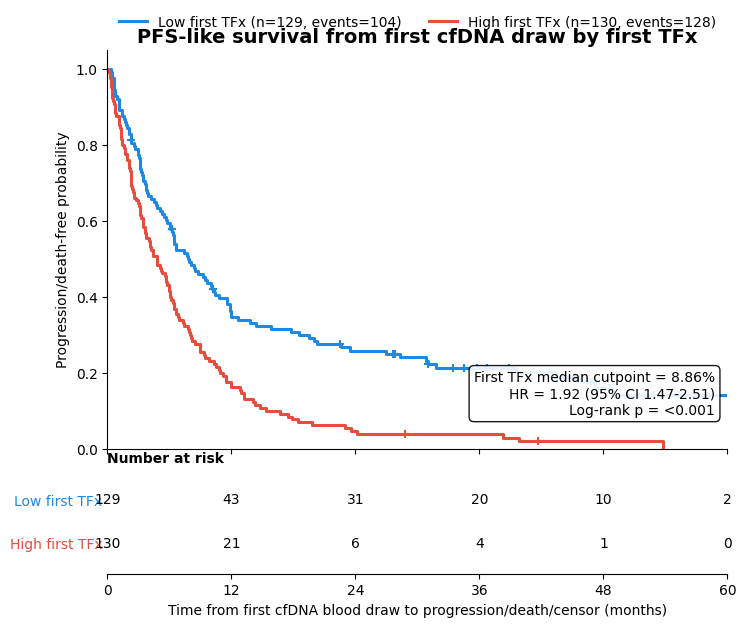


Saved KM plot:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_overall_abstract_259_first_TFx_KM_with_risk_table_HR_CI.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_overall_abstract_259_first_TFx_KM_with_risk_table_HR_CI.pdf

Saved KM summary:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_overall_abstract_259_first_TFx_KM_summary_HR_CI.csv

Saved risk table:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_overall_abstract_259_first_TFx_number_at_risk_table.csv

Saved survival-ready subset:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:1573: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


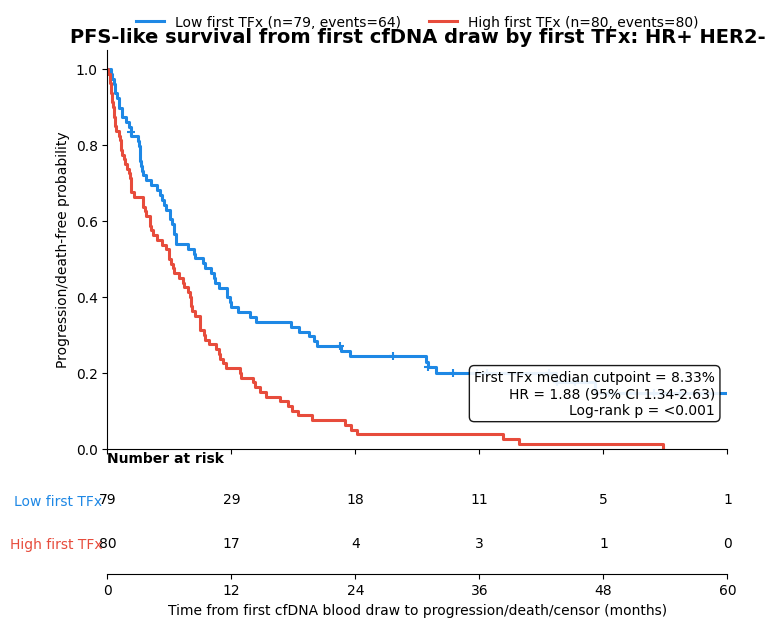


Saved KM plot:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRpos_HER2neg_abstract_259_first_TFx_KM_with_risk_table_HR_CI.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRpos_HER2neg_abstract_259_first_TFx_KM_with_risk_table_HR_CI.pdf

Saved KM summary:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRpos_HER2neg_abstract_259_first_TFx_KM_summary_HR_CI.csv

Saved risk table:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRpos_HER2neg_abstract_259_first_TFx_number_at_risk_table.csv

Saved survival-ready subset:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_projec

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:1573: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


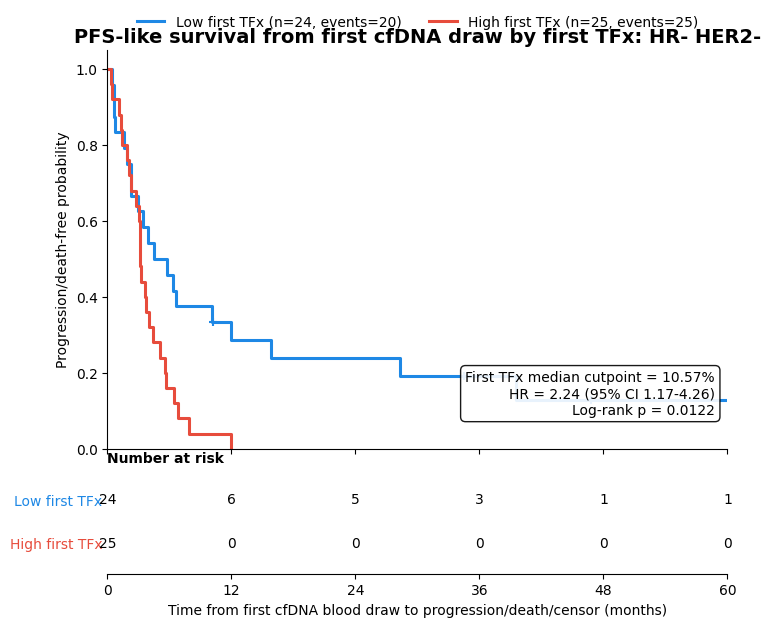


Saved KM plot:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRneg_HER2neg_abstract_259_first_TFx_KM_with_risk_table_HR_CI.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRneg_HER2neg_abstract_259_first_TFx_KM_with_risk_table_HR_CI.pdf

Saved KM summary:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRneg_HER2neg_abstract_259_first_TFx_KM_summary_HR_CI.csv

Saved risk table:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRneg_HER2neg_abstract_259_first_TFx_number_at_risk_table.csv

Saved survival-ready subset:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_projec

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:1573: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


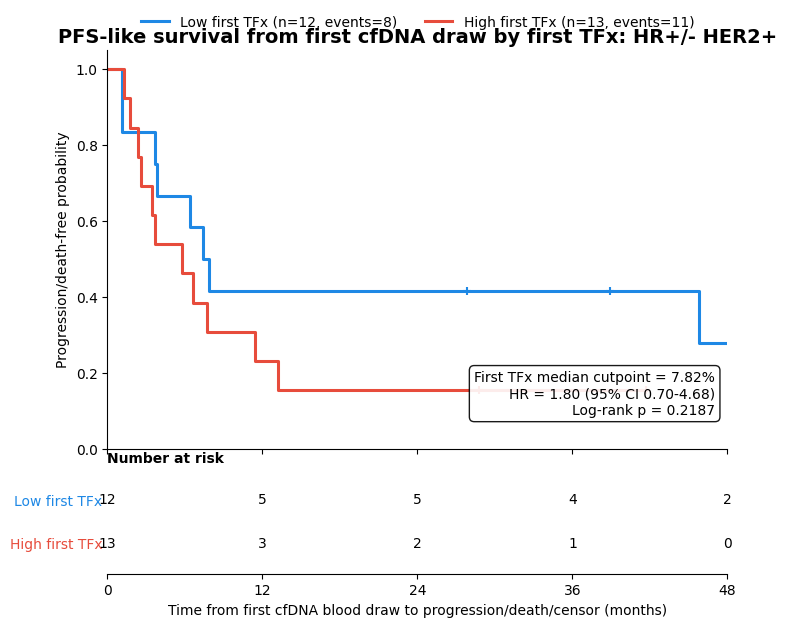


Saved KM plot:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRposneg_HER2pos_abstract_259_first_TFx_KM_with_risk_table_HR_CI.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRposneg_HER2pos_abstract_259_first_TFx_KM_with_risk_table_HR_CI.pdf

Saved KM summary:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRposneg_HER2pos_abstract_259_first_TFx_KM_summary_HR_CI.csv

Saved risk table:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract/PFS_Analysis1_first_available_draw_abstract_259.Earliest_Met_Diagnosis/PFS1_subtype_HRposneg_HER2pos_abstract_259_first_TFx_number_at_risk_table.csv

Saved survival-ready subset:
/ix1/alee/LO_LAB/Personal/Rahul/

In [10]:
# ============================================================
# PFS Analysis 1: Abstract-ready complete endpoint cohort
# First available cfDNA blood draw TFx vs time to next progression/death
#
# Main updates:
#   1. Exclude abstract-specific incomplete endpoint cases:
#        993-24 : no follow-up after cfDNA draw for PFS
#        586-2  : missing OS information
#        999-16 : missing OS information
#
#   2. Output saved under:
#        /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/Abstract
#
#   3. Overall PFS KM plot:
#        Low first TFx vs High first TFx
#
#   4. Subtype-wise PFS KM plots:
#        HR+ HER2-
#        HR- HER2-
#        HR+/- HER2+
#
#      HR+ HER2+ and HR- HER2+ are merged as HR+/- HER2+.
#
# Endpoint:
#   PFS-like interval from first available eligible cfDNA blood draw
#   to next documented progression or death.
#
# Predictor:
#   TFx at first available eligible cfDNA blood draw.
#
# Outcome:
#   PFS_time_from_draw = next progression/death/censor day - blood draw day.
#
# Event:
#   1 = progression or death after blood draw
#   0 = censored at OS/follow-up day
#
# TFx filtering:
#   No TFx <3% or TFx >=3% cutoff/filter is applied.
#
# Important:
#   This is a cfDNA-indexed PFS-like endpoint, not trial-defined RECIST PFS.
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, norm
from scipy.optimize import minimize_scalar


# ============================================================
# 1. Paths and settings
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

clinical_xlsx = BASE_DIR / "Clinical_data/AUP_ClinicalData_20260609.xlsx"
clinical_sheet = "AUP_ClinicalData_20260609.NO.DA"

blood_draws_xlsx = (
    BASE_DIR /
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)

blood_draws_sheet = "Blood_draws"

# ------------------------------------------------------------
# Receptor source used to define HR/HER2 subgroup
# ------------------------------------------------------------
# Options:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"

# RECEPTOR_SOURCE = "First_Primary"
RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"

VALID_RECEPTOR_SOURCES = {"First_Primary", "Earliest_Met_Diagnosis"}

if RECEPTOR_SOURCE not in VALID_RECEPTOR_SOURCES:
    raise ValueError(
        f"RECEPTOR_SOURCE must be one of {sorted(VALID_RECEPTOR_SOURCES)}; "
        f"got {RECEPTOR_SOURCE!r}"
    )

# ------------------------------------------------------------
# Abstract-specific complete endpoint exclusions
# ------------------------------------------------------------

EXCLUDE_PATIENTS = {"993-24", "586-2", "999-16"}

EXCLUSION_REASONS = {
    "993-24": "No follow-up after cfDNA draw for PFS calculation",
    "586-2": "Missing OS information",
    "999-16": "Missing OS information"
}

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

out_dir = (
    BASE_DIR /
    "Survival" /
    "Abstract" /
    f"PFS_Analysis1_first_available_draw_abstract_259.{RECEPTOR_SOURCE}"
)

out_dir.mkdir(parents=True, exist_ok=True)

# Days-to-months conversion for reporting/plotting.
DAYS_PER_MONTH = 365.25 / 12

# KM plot colors, matching locked AURORA style.
KM_COLORS = {
    "Low first TFx": "#1E88E5",
    "High first TFx": "#E74C3C"
}

print("Clinical file:")
print(clinical_xlsx)

print("\nBlood-draw file:")
print(blood_draws_xlsx)

print("\nReceptor source:")
print(RECEPTOR_SOURCE)

print("\nAbstract-specific excluded patients:")
print(sorted(EXCLUDE_PATIENTS))

print("\nOutput directory:")
print(out_dir)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_patient_id(x):
    """
    Clean patient_id for matching across clinical and blood-draw files.

    Examples:
      2        -> "2"
      2.0      -> "2"
      "2.0"    -> "2"
      "999-17" -> "999-17"
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def patient_sort_key(x):
    """
    Sort numeric patient IDs numerically and character IDs afterward.
    """
    try:
        return (0, float(x))
    except Exception:
        return (1, str(x))


def safe_numeric(x):
    return pd.to_numeric(x, errors="coerce")


def code_os_event(x):
    """
    Code OS_event.

    Dead                -> 1
    Alive with Disease  -> 0
    Lost to Follow Up   -> 0
    Lost to Follow-up   -> 0
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s == "dead":
        return 1

    if s in {"alive with disease", "lost to follow up", "lost to follow-up"}:
        return 0

    return pd.NA


def paste_unique(series, sep="; "):
    vals = []
    seen = set()

    for v in series:
        if pd.isna(v):
            continue

        s = str(v).strip()

        if s == "":
            continue

        if s not in seen:
            vals.append(s)
            seen.add(s)

    return sep.join(vals) if vals else pd.NA


def fmt_p(p):
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return "<0.001"
    return f"{p:.4f}"


def fmt_hr(hr, lo, hi):
    if pd.isna(hr) or pd.isna(lo) or pd.isna(hi):
        return "HR = NA"
    return f"HR = {hr:.2f} (95% CI {lo:.2f}-{hi:.2f})"


def fmt_median(x):
    if pd.isna(x):
        return "Not reached"
    return f"{x:.2f}"


def safe_name(x):
    """
    Convert labels into safe file names.
    """
    s = str(x)
    s = s.replace("+/-", "posneg")
    s = s.replace("+", "pos")
    s = s.replace("-", "neg")
    s = re.sub(r"\s+", "_", s)
    s = re.sub(r"[^A-Za-z0-9_]", "", s)
    return s


# ============================================================
# 3. Read Blood_draws sheet
# ============================================================

blood = pd.read_excel(
    blood_draws_xlsx,
    sheet_name=blood_draws_sheet,
    dtype=str
)

print("\n========== Blood_draws input ==========")
print("Rows:", blood.shape[0])
print("Columns:", blood.shape[1])
print(blood.columns.tolist())

required_blood_cols = [
    "patient_id",
    "Patient_Identifier",
    "Barcode",
    "Blood_Draw_Days_From_Primary_Diagnosis",
    "Tumor_Fraction_percent_from_CNV_annotation",
    "Treatment_context_at_draw"
]

missing_blood_cols = [c for c in required_blood_cols if c not in blood.columns]

if len(missing_blood_cols) > 0:
    raise ValueError(f"Missing required Blood_draws columns: {missing_blood_cols}")

blood["patient_id_clean"] = blood["patient_id"].apply(clean_patient_id)

blood["blood_draw_day"] = safe_numeric(
    blood["Blood_Draw_Days_From_Primary_Diagnosis"]
)

blood["TFx"] = safe_numeric(
    blood["Tumor_Fraction_percent_from_CNV_annotation"]
)

# If TFx accidentally appears as 0-1 fraction, convert to percent.
if blood["TFx"].dropna().shape[0] > 0:
    if blood["TFx"].dropna().max() <= 1:
        print("\nTFx appears to be 0-1 fraction; converting to percent.")
        blood["TFx"] = blood["TFx"] * 100

blood_draws = blood[
    blood["patient_id_clean"].notna()
    & blood["Barcode"].notna()
    & blood["blood_draw_day"].notna()
    & blood["TFx"].notna()
].copy()

print("\n========== Usable blood draws ==========")
print("Blood-draw rows:", blood_draws.shape[0])
print("Unique patients:", blood_draws["patient_id_clean"].nunique())
print("Unique barcodes:", blood_draws["Barcode"].nunique())
print("Rows with nonmissing TFx:", blood_draws["TFx"].notna().sum())

print("\nTreatment context distribution among usable blood draws:")
print(
    blood_draws["Treatment_context_at_draw"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)


# ============================================================
# 4. Read clinical file
# ============================================================

clinical = pd.read_excel(
    clinical_xlsx,
    sheet_name=clinical_sheet,
    dtype=str
)

print("\n========== Clinical input ==========")
print("Rows:", clinical.shape[0])
print("Columns:", clinical.shape[1])
print(clinical.columns.tolist())

required_clinical_cols = [
    "patient_id",
    "Category",
    "Days_From_Primary_Diagnosis",
    "EndTrt_Days_From_Primary_Diagnosis",
    "Treatment_Response",
    "OS_event",
    "ER_Status",
    "PR_Status",
    "HER2_Status"
]

missing_clinical_cols = [c for c in required_clinical_cols if c not in clinical.columns]

if len(missing_clinical_cols) > 0:
    raise ValueError(f"Missing required clinical columns: {missing_clinical_cols}")

# Optional columns used for annotation.
for optional_col in ["Met_Therapy_Line", "Regimen"]:
    if optional_col not in clinical.columns:
        clinical[optional_col] = pd.NA

clinical["patient_id_clean"] = clinical["patient_id"].apply(clean_patient_id)

clinical["Days_From_Primary_Diagnosis_num"] = safe_numeric(
    clinical["Days_From_Primary_Diagnosis"]
)

clinical["EndTrt_Days_From_Primary_Diagnosis_num"] = safe_numeric(
    clinical["EndTrt_Days_From_Primary_Diagnosis"]
)


# ============================================================
# 5. Build receptor-status subgroup table
# ============================================================
#
# Subgroups before merge:
#   HR+ HER2-
#   HR+ HER2+
#   HR- HER2-
#   HR- HER2+
#
# Merged subgroups for plotting:
#   HR+ HER2-
#   HR- HER2-
#   HR+/- HER2+
#
# HR+ HER2+ and HR- HER2+ are merged as HR+/- HER2+.
# ============================================================

def clean_receptor_status(x):
    """
    Standardize receptor status.

    Handles common values:
      Positive / Pos / +
      Negative / Neg / -
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s == "" or s in {"na", "nan", "none", "null", "unknown"}:
        return pd.NA

    if s in {"positive", "pos", "+", "1", "yes"}:
        return "Positive"

    if s in {"negative", "neg", "-", "0", "no"}:
        return "Negative"

    if "positive" in s or s.endswith("+"):
        return "Positive"

    if "negative" in s or s.endswith("-"):
        return "Negative"

    return pd.NA


def assign_subgroup(er_status, pr_status, her2_status):
    """
    Assign HR/HER2 subgroup.

    HR+   = ER+ or PR+
    HR-   = ER- and PR-
    HER2+ = HER2+
    HER2- = HER2-
    """

    er_pos = pd.notna(er_status) and er_status == "Positive"
    pr_pos = pd.notna(pr_status) and pr_status == "Positive"
    er_neg = pd.notna(er_status) and er_status == "Negative"
    pr_neg = pd.notna(pr_status) and pr_status == "Negative"

    if er_pos or pr_pos:
        hr_status = "HR+"
    elif er_neg and pr_neg:
        hr_status = "HR-"
    else:
        return pd.NA

    if pd.isna(her2_status):
        return pd.NA

    if her2_status == "Positive":
        her2_group = "HER2+"
    elif her2_status == "Negative":
        her2_group = "HER2-"
    else:
        return pd.NA

    return f"{hr_status} {her2_group}"


def merge_her2_positive_subgroup(x):
    """
    Merge HR+ HER2+ and HR- HER2+ as HR+/- HER2+.
    """

    if pd.isna(x):
        return pd.NA

    s = str(x).strip()
    s = s.replace("Her2", "HER2").replace("her2", "HER2")
    s = re.sub(r"\s+", " ", s)

    if s == "HR+ HER2-":
        return "HR+ HER2-"

    if s == "HR- HER2-":
        return "HR- HER2-"

    if s in {"HR+ HER2+", "HR- HER2+"}:
        return "HR+/- HER2+"

    return pd.NA


def receptor_source_mask(df, receptor_source):
    """
    Return source-specific clinical rows for receptor subgroup assignment.
    """

    cat = df["Category"].astype(str).str.strip().str.lower()

    if receptor_source == "First_Primary":
        return (
            cat.eq("first_primary")
            | cat.eq("primary")
            | cat.str.contains("first primary", na=False)
            | cat.str.contains("primary", na=False)
        )

    if receptor_source == "Earliest_Met_Diagnosis":
        return (
            cat.eq("earliest_met_diagnosis")
            | cat.eq("met_diagnosis")
            | cat.eq("metastatic diagnosis")
            | cat.str.contains("earliest met", na=False)
            | (
                cat.str.contains("met", na=False)
                & cat.str.contains("diagnosis", na=False)
            )
        )

    raise ValueError(f"Unsupported receptor_source: {receptor_source}")


clinical_receptor_all = clinical[
    clinical["patient_id_clean"].notna()
].copy()

clinical_receptor_all["ER_Status_clean"] = clinical_receptor_all["ER_Status"].apply(clean_receptor_status)
clinical_receptor_all["PR_Status_clean"] = clinical_receptor_all["PR_Status"].apply(clean_receptor_status)
clinical_receptor_all["HER2_Status_clean"] = clinical_receptor_all["HER2_Status"].apply(clean_receptor_status)

clinical_receptor_source = clinical_receptor_all[
    receptor_source_mask(clinical_receptor_all, RECEPTOR_SOURCE)
].copy()

clinical_receptor_source = clinical_receptor_source[
    clinical_receptor_source[
        ["ER_Status_clean", "PR_Status_clean", "HER2_Status_clean"]
    ].notna().any(axis=1)
].copy()

clinical_receptor_source = clinical_receptor_source.sort_values(
    [
        "patient_id_clean",
        "Days_From_Primary_Diagnosis_num",
        "Category"
    ],
    na_position="last"
)

# Use earliest source-specific row per patient.
patient_subgroups = (
    clinical_receptor_source
    .drop_duplicates(subset=["patient_id_clean"], keep="first")
    [
        [
            "patient_id_clean",
            "Category",
            "Days_From_Primary_Diagnosis_num",
            "ER_Status_clean",
            "PR_Status_clean",
            "HER2_Status_clean"
        ]
    ]
    .rename(
        columns={
            "Category": "Receptor_source_category",
            "Days_From_Primary_Diagnosis_num": "Receptor_source_day",
            "ER_Status_clean": "ER_Status_patient",
            "PR_Status_clean": "PR_Status_patient",
            "HER2_Status_clean": "HER2_Status_patient"
        }
    )
)

patient_subgroups["Subgroups"] = patient_subgroups.apply(
    lambda r: assign_subgroup(
        r["ER_Status_patient"],
        r["PR_Status_patient"],
        r["HER2_Status_patient"]
    ),
    axis=1
)

patient_subgroups["Subgroups_HER2pos_combined"] = patient_subgroups["Subgroups"].apply(
    merge_her2_positive_subgroup
)

patient_subgroups["RECEPTOR_SOURCE"] = RECEPTOR_SOURCE

patient_subgroups_file = out_dir / f"PFS1_patient_level_receptor_subgroups_{RECEPTOR_SOURCE}.csv"
patient_subgroups.to_csv(patient_subgroups_file, index=False)

print("\n========== Patient-level receptor subgroups ==========")
print("RECEPTOR_SOURCE:", RECEPTOR_SOURCE)
print("Source-specific receptor rows:", clinical_receptor_source.shape[0])
print("Patients with source-specific receptor rows:", patient_subgroups.shape[0])

print("\nOriginal subgroup distribution:")
print(
    patient_subgroups["Subgroups"]
    .fillna("Missing/Unknown")
    .value_counts(dropna=False)
    .to_string()
)

print("\nMerged subgroup distribution:")
print(
    patient_subgroups["Subgroups_HER2pos_combined"]
    .fillna("Missing/Unknown")
    .value_counts(dropna=False)
    .to_string()
)

print("\nSaved receptor subgroup table:")
print(patient_subgroups_file)


# ============================================================
# 6. Build progression-event table
# ============================================================

progression_rows = clinical[
    clinical["patient_id_clean"].notna()
    & clinical["Treatment_Response"].astype(str).str.strip().eq("Progression")
    & clinical["EndTrt_Days_From_Primary_Diagnosis_num"].notna()
].copy()

progression_rows["progression_day"] = progression_rows[
    "EndTrt_Days_From_Primary_Diagnosis_num"
]

progression_events = (
    progression_rows
    .groupby(["patient_id_clean", "progression_day"], dropna=False)
    .agg(
        progression_categories=("Category", paste_unique),
        progression_lines=("Met_Therapy_Line", paste_unique),
        progression_regimens=("Regimen", paste_unique),
        n_progression_rows=("Treatment_Response", "size")
    )
    .reset_index()
)

progression_events_file = out_dir / "PFS1_progression_event_days_collapsed.csv"
progression_events.to_csv(progression_events_file, index=False)

print("\n========== Progression event table ==========")
print("Progression rows:", progression_rows.shape[0])
print("Collapsed progression patient-days:", progression_events.shape[0])
print("Patients with progression events:", progression_events["patient_id_clean"].nunique())


# ============================================================
# 7. Build OS/death/follow-up table
# ============================================================

os_rows = clinical[
    clinical["patient_id_clean"].notna()
    & clinical["Category"].astype(str).str.strip().eq("Overall_Survival_days")
].copy()

os_rows["OS_days"] = os_rows["Days_From_Primary_Diagnosis_num"]
os_rows["OS_event_coded"] = os_rows["OS_event"].apply(code_os_event)

print("\n========== OS rows ==========")
print("OS rows:", os_rows.shape[0])
print("Unique patients with OS rows:", os_rows["patient_id_clean"].nunique())

print("\nRaw OS_event distribution:")
print(os_rows["OS_event"].fillna("Missing").value_counts(dropna=False).to_string())

print("\nCoded OS_event distribution:")
print(os_rows["OS_event_coded"].fillna("Missing").value_counts(dropna=False).to_string())

os_patient_rows = []

for pid, sub in os_rows.groupby("patient_id_clean", dropna=False):
    if pd.isna(pid):
        continue

    os_days = sub["OS_days"].max(skipna=True)

    event_vals = sub["OS_event_coded"].dropna().astype(int).tolist()

    if 1 in event_vals:
        os_event = 1
        death_day = os_days
    elif 0 in event_vals:
        os_event = 0
        death_day = np.nan
    else:
        os_event = pd.NA
        death_day = np.nan

    os_patient_rows.append({
        "patient_id_clean": pid,
        "OS_days": os_days,
        "OS_event": os_event,
        "death_day": death_day,
        "OS_event_raw_all": paste_unique(sub["OS_event"]),
        "n_OS_rows": sub.shape[0]
    })

os_patient = pd.DataFrame(os_patient_rows)

os_patient_file = out_dir / "PFS1_patient_level_OS_followup_death.csv"
os_patient.to_csv(os_patient_file, index=False)

print("\n========== Patient-level OS/follow-up table ==========")
print("Patients:", os_patient.shape[0])
print("Deaths:", int((os_patient["OS_event"] == 1).sum()))
print("Censored/alive/LTFU:", int((os_patient["OS_event"] == 0).sum()))
print("Missing OS_event:", os_patient["OS_event"].isna().sum())


# ============================================================
# 8. Build blood-draw-level PFS table
# ============================================================

progression_by_patient = {
    pid: np.sort(sub["progression_day"].dropna().unique())
    for pid, sub in progression_events.groupby("patient_id_clean")
}

os_by_patient = os_patient.set_index("patient_id_clean").to_dict(orient="index")

pfs_rows = []

for _, row in blood_draws.iterrows():
    pid = row["patient_id_clean"]
    draw_day = row["blood_draw_day"]

    # -------------------------
    # Next progression after draw
    # -------------------------
    prog_days = progression_by_patient.get(pid, np.array([]))
    future_prog_days = prog_days[prog_days > draw_day]

    if len(future_prog_days) > 0:
        next_prog_day = float(future_prog_days[0])
    else:
        next_prog_day = np.nan

    # -------------------------
    # Death/follow-up
    # -------------------------
    os_info = os_by_patient.get(pid, {})

    os_days = os_info.get("OS_days", np.nan)
    os_event = os_info.get("OS_event", pd.NA)
    death_day = os_info.get("death_day", np.nan)
    os_event_raw_all = os_info.get("OS_event_raw_all", pd.NA)

    future_death_day = np.nan

    if pd.notna(death_day) and pd.notna(draw_day):
        if death_day > draw_day:
            future_death_day = float(death_day)

    # -------------------------
    # Determine event day/type
    # -------------------------
    candidate_events = []

    if pd.notna(next_prog_day):
        candidate_events.append(("Progression", next_prog_day))

    if pd.notna(future_death_day):
        candidate_events.append(("Death", future_death_day))

    if len(candidate_events) > 0:
        candidate_events = sorted(candidate_events, key=lambda x: x[1])
        pfs_event_type = candidate_events[0][0]
        pfs_event_day = candidate_events[0][1]
        pfs_event = 1
        pfs_time = pfs_event_day - draw_day
        censor_day = np.nan

    else:
        pfs_event_type = "Censored"
        pfs_event_day = np.nan
        pfs_event = 0

        if pd.notna(os_days) and os_days > draw_day:
            censor_day = float(os_days)
            pfs_time = censor_day - draw_day
        else:
            censor_day = np.nan
            pfs_time = np.nan

    # -------------------------
    # QC flag
    # -------------------------
    qc_flags = []

    if pd.isna(os_days):
        qc_flags.append("Missing OS/follow-up day")

    if pd.notna(os_days) and os_days <= draw_day:
        qc_flags.append("OS/follow-up day <= blood draw day; no follow-up after draw")

    if pd.notna(pfs_time) and pfs_time < 0:
        qc_flags.append("Negative PFS time")

    if pd.notna(pfs_time) and pfs_time == 0:
        qc_flags.append("Zero PFS time")

    qc_flag = "; ".join(qc_flags) if len(qc_flags) > 0 else pd.NA

    pfs_rows.append({
        "patient_id": row["patient_id"],
        "patient_id_clean": pid,
        "Patient_Identifier": row.get("Patient_Identifier", pd.NA),
        "Barcode": row["Barcode"],
        "blood_draw_day": draw_day,
        "TFx": row["TFx"],
        "Treatment_context_at_draw": row.get("Treatment_context_at_draw", pd.NA),
        "Active_treatment_at_draw": row.get("Active_treatment_at_draw", pd.NA),
        "draw_num": row.get("draw_num", pd.NA),
        "next_progression_day_after_draw": next_prog_day,
        "death_day_after_draw": future_death_day,
        "OS_days_or_last_followup": os_days,
        "OS_event_raw_all": os_event_raw_all,
        "PFS_event_day": pfs_event_day,
        "PFS_censor_day": censor_day,
        "PFS_time_from_draw": pfs_time,
        "PFS_event": pfs_event,
        "PFS_event_type": pfs_event_type,
        "PFS_QC_Flag": qc_flag
    })

blood_draw_pfs = pd.DataFrame(pfs_rows)

blood_draw_pfs["PFS_time_from_draw_months"] = (
    blood_draw_pfs["PFS_time_from_draw"] / DAYS_PER_MONTH
)

blood_draw_pfs_file = out_dir / "PFS1_blood_draw_level_TFx_PFS_from_draw_before_abstract_exclusion.csv"
blood_draw_pfs.to_csv(blood_draw_pfs_file, index=False)

print("\n========== Blood-draw-level PFS table ==========")
print("Rows:", blood_draw_pfs.shape[0])
print("Patients:", blood_draw_pfs["patient_id_clean"].nunique())
print("Rows with PFS time:", blood_draw_pfs["PFS_time_from_draw"].notna().sum())

print("\nPFS event type distribution:")
print(
    blood_draw_pfs["PFS_event_type"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\nPFS QC flag distribution:")
print(
    blood_draw_pfs["PFS_QC_Flag"]
    .fillna("No QC flag")
    .value_counts(dropna=False)
    .head(20)
    .to_string()
)


# ============================================================
# 9. Create first available eligible cfDNA draw per patient
# ============================================================

eligible_draws = blood_draw_pfs[
    blood_draw_pfs["TFx"].notna()
    & blood_draw_pfs["blood_draw_day"].notna()
    & blood_draw_pfs["PFS_time_from_draw"].notna()
    & (blood_draw_pfs["PFS_time_from_draw"] > 0)
].copy()

eligible_draws = eligible_draws.sort_values(
    ["patient_id_clean", "blood_draw_day", "Barcode"]
)

first_draw = (
    eligible_draws
    .groupby("patient_id_clean", as_index=False)
    .first()
)

first_draw = first_draw.rename(
    columns={
        "blood_draw_day": "first_draw_day",
        "Barcode": "first_draw_barcode",
        "TFx": "first_TFx",
        "Treatment_context_at_draw": "Treatment_context_at_first_draw",
        "Active_treatment_at_draw": "Active_treatment_at_first_draw",
        "PFS_time_from_draw": "PFS_time_from_first_draw",
        "PFS_time_from_draw_months": "PFS_time_from_first_draw_months",
        "PFS_event": "PFS_event_from_first_draw",
        "PFS_event_type": "PFS_event_type_from_first_draw"
    }
)

# Add receptor subgroup annotation.
first_draw = first_draw.merge(
    patient_subgroups[
        [
            "patient_id_clean",
            "Subgroups",
            "Subgroups_HER2pos_combined"
        ]
    ],
    on="patient_id_clean",
    how="left"
)

first_draw_before_exclusion_file = out_dir / "PFS1_first_available_draw_per_patient_before_abstract_exclusion.csv"
first_draw.to_csv(first_draw_before_exclusion_file, index=False)

print("\n========== PFS Analysis 1 before abstract exclusion ==========")
print("Patients:", first_draw.shape[0])
print("Events:", int((first_draw["PFS_event_from_first_draw"] == 1).sum()))
print("Censored:", int((first_draw["PFS_event_from_first_draw"] == 0).sum()))

print("\nSubgroup distribution before abstract exclusion:")
print(
    first_draw["Subgroups_HER2pos_combined"]
    .fillna("Missing/Unknown")
    .value_counts(dropna=False)
    .to_string()
)


# ============================================================
# 10. Abstract-specific exclusion
# ============================================================

print("\n========== Abstract-specific exclusions ==========")
print("Patients requested for exclusion:")
print(sorted(EXCLUDE_PATIENTS))

excluded_from_first_draw = first_draw[
    first_draw["patient_id_clean"].isin(EXCLUDE_PATIENTS)
].copy()

excluded_from_first_draw["exclusion_reason"] = excluded_from_first_draw["patient_id_clean"].map(
    EXCLUSION_REASONS
)

excluded_from_first_draw_file = out_dir / "PFS1_excluded_patients_found_in_first_draw_table_QC.csv"
excluded_from_first_draw.to_csv(excluded_from_first_draw_file, index=False)

print("\nExcluded patients found in first-draw table:")
if excluded_from_first_draw.shape[0] > 0:
    print(
        excluded_from_first_draw[
            [
                "patient_id_clean",
                "first_draw_barcode",
                "first_draw_day",
                "first_TFx",
                "PFS_time_from_first_draw",
                "PFS_event_from_first_draw",
                "PFS_event_type_from_first_draw",
                "exclusion_reason"
            ]
        ].to_string(index=False)
    )
else:
    print("None of the requested excluded patients were present in first_draw.")

excluded_all_blood_draw_rows = blood_draw_pfs[
    blood_draw_pfs["patient_id_clean"].isin(EXCLUDE_PATIENTS)
].copy()

excluded_all_blood_draw_rows["exclusion_reason"] = excluded_all_blood_draw_rows["patient_id_clean"].map(
    EXCLUSION_REASONS
)

excluded_all_blood_draw_rows_file = out_dir / "PFS1_excluded_patients_all_blood_draw_rows_QC.csv"
excluded_all_blood_draw_rows.to_csv(excluded_all_blood_draw_rows_file, index=False)

# Final abstract-ready first-draw PFS table.
first_draw = first_draw[
    ~first_draw["patient_id_clean"].isin(EXCLUDE_PATIENTS)
].copy()

first_draw = first_draw.sort_values(
    by="patient_id_clean",
    key=lambda s: s.map(patient_sort_key)
)

first_draw_file = out_dir / "PFS1_first_available_draw_per_patient_abstract_259.csv"
first_draw.to_csv(first_draw_file, index=False)

# Also save blood-draw-level PFS after abstract exclusions.
blood_draw_pfs_abstract = blood_draw_pfs[
    ~blood_draw_pfs["patient_id_clean"].isin(EXCLUDE_PATIENTS)
].copy()

blood_draw_pfs_abstract_file = out_dir / "PFS1_blood_draw_level_TFx_PFS_from_draw_abstract_exclusions_applied.csv"
blood_draw_pfs_abstract.to_csv(blood_draw_pfs_abstract_file, index=False)

print("\n========== PFS Analysis 1 after abstract exclusion ==========")
print("Patients:", first_draw.shape[0])
print("Events:", int((first_draw["PFS_event_from_first_draw"] == 1).sum()))
print("Censored:", int((first_draw["PFS_event_from_first_draw"] == 0).sum()))

print("\nSubgroup distribution after abstract exclusion:")
print(
    first_draw["Subgroups_HER2pos_combined"]
    .fillna("Missing/Unknown")
    .value_counts(dropna=False)
    .to_string()
)

if first_draw.shape[0] != 259:
    print(
        "\nWARNING: Final PFS abstract-ready first-draw cohort is not 259 patients. "
        "Please check excluded patient IDs and starting cohort size."
    )
else:
    print("\nPASS: Final PFS abstract-ready first-draw cohort contains 259 patients.")


# ============================================================
# 11. KM and Cox helper functions
# ============================================================

def km_curve(durations, events):
    """
    Manual Kaplan-Meier estimator.
    """
    data = pd.DataFrame({
        "time": pd.to_numeric(durations, errors="coerce"),
        "event": pd.to_numeric(events, errors="coerce")
    }).dropna()

    data = data.sort_values("time")

    event_times = sorted(data.loc[data["event"] == 1, "time"].unique())

    x = [0.0]
    y = [1.0]

    surv_prob = 1.0
    median_survival = np.nan
    rows = []

    for t in event_times:
        n_at_risk = int((data["time"] >= t).sum())
        n_events = int(((data["time"] == t) & (data["event"] == 1)).sum())
        n_censored = int(((data["time"] == t) & (data["event"] == 0)).sum())

        if n_at_risk > 0:
            surv_prob = surv_prob * (1 - n_events / n_at_risk)

        x.append(float(t))
        y.append(float(surv_prob))

        rows.append({
            "time": t,
            "n_at_risk": n_at_risk,
            "n_events": n_events,
            "n_censored": n_censored,
            "survival": surv_prob
        })

        if pd.isna(median_survival) and surv_prob <= 0.5:
            median_survival = t

    max_time = data["time"].max()

    if len(x) == 1 or x[-1] < max_time:
        x.append(float(max_time))
        y.append(float(surv_prob))

    return np.array(x), np.array(y), pd.DataFrame(rows), median_survival


def survival_at_censor_times(event_table, censor_times):
    surv_vals = []

    for t in censor_times:
        sub = event_table[event_table["time"] <= t]

        if sub.empty:
            surv_vals.append(1.0)
        else:
            surv_vals.append(float(sub.iloc[-1]["survival"]))

    return np.array(surv_vals)


def logrank_two_group(df, time_col, event_col, group_col, group_a, group_b):
    d = df[df[group_col].isin([group_a, group_b])].copy()

    event_times = sorted(d.loc[d[event_col] == 1, time_col].dropna().unique())

    O_a = 0.0
    E_a = 0.0
    V_a = 0.0

    for t in event_times:
        n_a = ((d[group_col] == group_a) & (d[time_col] >= t)).sum()
        n_b = ((d[group_col] == group_b) & (d[time_col] >= t)).sum()
        n_total = n_a + n_b

        d_a = (
            (d[group_col] == group_a)
            & (d[time_col] == t)
            & (d[event_col] == 1)
        ).sum()

        d_b = (
            (d[group_col] == group_b)
            & (d[time_col] == t)
            & (d[event_col] == 1)
        ).sum()

        d_total = d_a + d_b

        if n_total <= 1 or d_total == 0:
            continue

        e_a = d_total * (n_a / n_total)

        v_a = (
            n_a * n_b * d_total * (n_total - d_total)
        ) / (
            (n_total ** 2) * (n_total - 1)
        )

        O_a += d_a
        E_a += e_a
        V_a += v_a

    if V_a > 0:
        chi_sq = ((O_a - E_a) ** 2) / V_a
        p_value = chi2.sf(chi_sq, df=1)
    else:
        chi_sq = np.nan
        p_value = np.nan

    return chi_sq, p_value


def coxph_binary_hr_ci(df, time_col, event_col, group_col, high_group):
    """
    Univariable Cox proportional hazards model for a binary group.

    Contrast:
      high_group vs reference group

    Uses Breslow approximation for tied event times.
    """

    d = df[[time_col, event_col, group_col]].dropna().copy()

    d["time"] = pd.to_numeric(d[time_col], errors="coerce")
    d["event"] = pd.to_numeric(d[event_col], errors="coerce")
    d["x"] = np.where(d[group_col] == high_group, 1.0, 0.0)

    d = d.dropna(subset=["time", "event", "x"]).copy()
    d = d[d["time"] >= 0].copy()

    if d.shape[0] == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    if d["event"].sum() == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    if d["x"].nunique() < 2:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    event_times = np.sort(d.loc[d["event"] == 1, "time"].unique())

    def neg_loglik(beta):
        beta = float(beta)
        loglik = 0.0

        for t in event_times:
            event_set = d[(d["time"] == t) & (d["event"] == 1)]
            risk_set = d[d["time"] >= t]

            d_t = event_set.shape[0]

            xb_event_sum = beta * event_set["x"].sum()
            risk_sum = np.exp(beta * risk_set["x"]).sum()

            if risk_sum <= 0:
                continue

            loglik += xb_event_sum - d_t * np.log(risk_sum)

        return -loglik

    fit = minimize_scalar(
        neg_loglik,
        bounds=(-10, 10),
        method="bounded"
    )

    if not fit.success:
        return np.nan, np.nan, np.nan, np.nan, np.nan, np.nan

    beta_hat = float(fit.x)

    information = 0.0

    for t in event_times:
        event_set = d[(d["time"] == t) & (d["event"] == 1)]
        risk_set = d[d["time"] >= t]

        d_t = event_set.shape[0]

        weights = np.exp(beta_hat * risk_set["x"])
        s0 = weights.sum()
        s1 = (risk_set["x"] * weights).sum()
        s2 = ((risk_set["x"] ** 2) * weights).sum()

        if s0 <= 0:
            continue

        information += d_t * ((s2 / s0) - ((s1 / s0) ** 2))

    if information <= 0:
        return np.nan, np.nan, np.nan, beta_hat, np.nan, np.nan

    se_beta = np.sqrt(1 / information)

    hr = np.exp(beta_hat)
    ci_low = np.exp(beta_hat - 1.96 * se_beta)
    ci_high = np.exp(beta_hat + 1.96 * se_beta)

    z = beta_hat / se_beta
    wald_p = 2 * norm.sf(abs(z))

    return hr, ci_low, ci_high, beta_hat, se_beta, wald_p


def make_time_ticks(max_months):
    """
    Create clean x-axis and risk-table time points.
    """
    if pd.isna(max_months) or max_months <= 0:
        return np.array([0, 6, 12, 18, 24, 30, 36])

    if max_months <= 36:
        tick_interval = 6
    elif max_months <= 84:
        tick_interval = 12
    else:
        tick_interval = 24

    x_ticks = np.arange(
        0,
        np.ceil(max_months / tick_interval) * tick_interval + tick_interval,
        tick_interval
    )

    x_ticks = x_ticks[x_ticks <= (max_months + tick_interval * 0.25)]

    if len(x_ticks) == 0:
        x_ticks = np.array([0, tick_interval])

    return x_ticks


def number_at_risk(df, time_col, group_col, group_order, x_ticks):
    rows = []

    for group in group_order:
        sub = df[df[group_col] == group].copy()
        row = {"group": group}

        for t in x_ticks:
            row[t] = int((sub[time_col] >= t).sum())

        rows.append(row)

    return pd.DataFrame(rows)


# ============================================================
# 12. Reusable KM plotting function
# ============================================================

def run_pfs_km_analysis(
    data,
    analysis_label,
    output_prefix,
    subtype_label="Overall",
    cutpoint_description="Median first TFx cutpoint"
):
    """
    Run high/low first TFx KM analysis for overall or subtype-specific data.
    """

    data = data.copy()

    print("\n============================================================")
    print("Running PFS KM analysis:", analysis_label)
    print("============================================================")

    if data.shape[0] == 0:
        print("Skipping: no rows.")
        return None

    n_patients = data.shape[0]
    n_events = int((data["PFS_event_from_first_draw"] == 1).sum())
    n_censored = int((data["PFS_event_from_first_draw"] == 0).sum())

    print("Patients:", n_patients)
    print("Events:", n_events)
    print("Censored:", n_censored)

    if n_patients < 6:
        print("Skipping: too few patients.")
        return None

    if n_events < 2:
        print("Skipping: too few events.")
        return None

    # --------------------------------------------------------
    # Median first TFx cutpoint for this analysis cohort
    # --------------------------------------------------------
    first_tfx_cut = data["first_TFx"].median()

    data["first_TFx_group"] = np.where(
        data["first_TFx"] >= first_tfx_cut,
        "High first TFx",
        "Low first TFx"
    )

    print(f"{cutpoint_description}: {first_tfx_cut:.4f}%")
    print(data["first_TFx_group"].value_counts().to_string())

    if data["first_TFx_group"].nunique() < 2:
        print("Skipping: only one TFx group.")
        return None

    time_col = "PFS_time_from_first_draw_months"
    event_col = "PFS_event_from_first_draw"
    group_col = "first_TFx_group"

    group_order = ["Low first TFx", "High first TFx"]

    # --------------------------------------------------------
    # Log-rank
    # --------------------------------------------------------
    chi_sq, logrank_p = logrank_two_group(
        data,
        time_col=time_col,
        event_col=event_col,
        group_col=group_col,
        group_a="Low first TFx",
        group_b="High first TFx"
    )

    print("Log-rank chi-square:", chi_sq)
    print("Log-rank p-value:", logrank_p)

    # --------------------------------------------------------
    # Cox HR
    # --------------------------------------------------------
    cox_hr, cox_ci_low, cox_ci_high, cox_beta, cox_se, cox_p = coxph_binary_hr_ci(
        data,
        time_col=time_col,
        event_col=event_col,
        group_col=group_col,
        high_group="High first TFx"
    )

    print("Cox HR high vs low:", cox_hr)
    print("Cox 95% CI:", cox_ci_low, cox_ci_high)
    print("Cox p:", cox_p)

    # --------------------------------------------------------
    # Save survival-ready subset
    # --------------------------------------------------------
    survival_ready_file = out_dir / f"{output_prefix}_survival_ready_table.csv"
    data.to_csv(survival_ready_file, index=False)

    # --------------------------------------------------------
    # Risk table ticks
    # --------------------------------------------------------
    max_months = data[time_col].max(skipna=True)

    if pd.isna(max_months) or max_months <= 0:
        print("Skipping: invalid max PFS time.")
        return None

    x_ticks = make_time_ticks(max_months)

    risk_table = number_at_risk(
        data,
        time_col=time_col,
        group_col=group_col,
        group_order=group_order,
        x_ticks=x_ticks
    )

    risk_table_file = out_dir / f"{output_prefix}_number_at_risk_table.csv"
    risk_table.to_csv(risk_table_file, index=False)

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------
    fig = plt.figure(figsize=(8.0, 6.8))

    gs = fig.add_gridspec(
        nrows=2,
        ncols=1,
        height_ratios=[3.8, 1.0],
        hspace=0.08
    )

    ax = fig.add_subplot(gs[0])
    ax_risk = fig.add_subplot(gs[1], sharex=ax)

    km_summary_rows = []

    for group in group_order:
        sub = data[data[group_col] == group].copy()

        x, y, event_table, median_pfs = km_curve(
            sub[time_col],
            sub[event_col]
        )

        n_group = sub.shape[0]
        n_group_events = int((sub[event_col] == 1).sum())
        n_group_censored = int((sub[event_col] == 0).sum())

        color = KM_COLORS.get(group, None)

        ax.step(
            x,
            y,
            where="post",
            linewidth=2.2,
            color=color,
            label=f"{group} (n={n_group}, events={n_group_events})"
        )

        censor_times = sub.loc[sub[event_col] == 0, time_col].dropna().values
        censor_y = survival_at_censor_times(event_table, censor_times)

        if len(censor_times) > 0:
            ax.scatter(
                censor_times,
                censor_y,
                marker="+",
                s=40,
                color=color,
                linewidths=1.5
            )

        km_summary_rows.append({
            "analysis_label": analysis_label,
            "subtype_label": subtype_label,
            "receptor_source": RECEPTOR_SOURCE,
            "subtype_merge": "HR+ HER2+ and HR- HER2+ merged as HR+/- HER2+",
            "tfx_filter": "No TFx cutoff/filter applied",
            "pfs_endpoint": "PFS-like survival from first cfDNA draw",
            "first_TFx_group": group,
            "n_patients_total_analysis": n_patients,
            "n_events_total_analysis": n_events,
            "n_censored_total_analysis": n_censored,
            "n_patients_group": n_group,
            "n_events_group": n_group_events,
            "n_censored_group": n_group_censored,
            "median_PFS_from_first_draw_months": median_pfs,
            "median_PFS_from_first_draw_months_formatted": fmt_median(median_pfs),
            "first_TFx_cutpoint": first_tfx_cut,
            "logrank_chi_square": chi_sq,
            "logrank_p_value": logrank_p,
            "cox_contrast": "High first TFx vs Low first TFx",
            "cox_HR_high_vs_low": cox_hr,
            "cox_HR_lower_95CI_high_vs_low": cox_ci_low,
            "cox_HR_upper_95CI_high_vs_low": cox_ci_high,
            "cox_beta_high_vs_low": cox_beta,
            "cox_SE_high_vs_low": cox_se,
            "cox_p_value_high_vs_low": cox_p
        })

    # --------------------------------------------------------
    # Main KM plot styling
    # --------------------------------------------------------
    ax.set_title(
        analysis_label,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylabel("Progression/death-free probability")
    ax.set_ylim(0, 1.05)
    ax.set_xlim(0, x_ticks.max() if len(x_ticks) > 0 else max_months)
    ax.set_xticks(x_ticks)

    ax.grid(False)
    ax.tick_params(axis="x", labelbottom=False)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    annotation_text = (
        f"First TFx median cutpoint = {first_tfx_cut:.2f}%\n"
        f"{fmt_hr(cox_hr, cox_ci_low, cox_ci_high)}\n"
        f"Log-rank p = {fmt_p(logrank_p)}"
    )

    ax.text(
        0.98,
        0.08,
        annotation_text,
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="black",
            alpha=0.90
        )
    )

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 1.12),
        ncol=2,
        frameon=False
    )

    # --------------------------------------------------------
    # Risk table
    # --------------------------------------------------------
    ax_risk.set_ylim(-0.7, len(group_order) - 0.3)
    ax_risk.set_yticks(range(len(group_order)))
    ax_risk.set_yticklabels(group_order)
    ax_risk.invert_yaxis()

    ax_risk.set_xlabel(
        "Time from first cfDNA blood draw to progression/death/censor (months)"
    )

    ax_risk.set_xticks(x_ticks)

    for spine in ["top", "right", "left"]:
        ax_risk.spines[spine].set_visible(False)

    ax_risk.tick_params(axis="y", length=0)
    ax_risk.grid(False)

    ax_risk.text(
        0,
        -0.95,
        "Number at risk",
        ha="left",
        va="center",
        fontsize=10,
        fontweight="bold",
        transform=ax_risk.transData
    )

    for row_i, group in enumerate(group_order):
        sub = data[data[group_col] == group].copy()
        color = KM_COLORS.get(group, "black")

        ax_risk.get_yticklabels()[row_i].set_color(color)

        for t in x_ticks:
            n_at_risk = int((sub[time_col] >= t).sum())

            ax_risk.text(
                t,
                row_i,
                str(n_at_risk),
                ha="center",
                va="center",
                fontsize=10
            )

    plt.tight_layout()

    km_png = out_dir / f"{output_prefix}_KM_with_risk_table_HR_CI.png"
    km_pdf = out_dir / f"{output_prefix}_KM_with_risk_table_HR_CI.pdf"

    plt.savefig(km_png, dpi=300, bbox_inches="tight")
    plt.savefig(km_pdf, bbox_inches="tight")

    plt.show()
    plt.close()

    # --------------------------------------------------------
    # Save summary
    # --------------------------------------------------------
    km_summary = pd.DataFrame(km_summary_rows)

    km_summary_file = out_dir / f"{output_prefix}_KM_summary_HR_CI.csv"
    km_summary.to_csv(km_summary_file, index=False)

    print("\nSaved KM plot:")
    print(km_png)
    print(km_pdf)

    print("\nSaved KM summary:")
    print(km_summary_file)

    print("\nSaved risk table:")
    print(risk_table_file)

    print("\nSaved survival-ready subset:")
    print(survival_ready_file)

    return km_summary


# ============================================================
# 13. Overall KM plot
# ============================================================

all_summary_tables = []

overall_summary = run_pfs_km_analysis(
    data=first_draw,
    analysis_label="PFS-like survival from first cfDNA draw by first TFx",
    output_prefix="PFS1_overall_abstract_259_first_TFx",
    subtype_label="Overall",
    cutpoint_description="Overall cohort median first TFx cutpoint"
)

if overall_summary is not None:
    all_summary_tables.append(overall_summary)


# ============================================================
# 14. Subtype-wise KM plots
# ============================================================

subtype_order = [
    "HR+ HER2-",
    "HR- HER2-",
    "HR+/- HER2+"
]

for subtype in subtype_order:

    sub_df = first_draw[
        first_draw["Subgroups_HER2pos_combined"] == subtype
    ].copy()

    output_prefix = (
        "PFS1_subtype_"
        + safe_name(subtype)
        + "_abstract_259_first_TFx"
    )

    subtype_summary = run_pfs_km_analysis(
        data=sub_df,
        analysis_label=f"PFS-like survival from first cfDNA draw by first TFx: {subtype}",
        output_prefix=output_prefix,
        subtype_label=subtype,
        cutpoint_description=f"Subtype-specific median first TFx cutpoint: {subtype}"
    )

    if subtype_summary is not None:
        all_summary_tables.append(subtype_summary)


# ============================================================
# 15. Save combined overall + subtype summary
# ============================================================

if len(all_summary_tables) > 0:

    combined_summary = pd.concat(
        all_summary_tables,
        ignore_index=True
    )

    combined_summary_file = out_dir / "PFS1_combined_overall_and_subtype_KM_summary_abstract_259_HR_CI.csv"
    combined_summary.to_csv(combined_summary_file, index=False)

    print("\n============================================================")
    print("Saved combined overall + subtype PFS KM summary:")
    print(combined_summary_file)
    print("============================================================")

    print(combined_summary.to_string(index=False))

else:
    print("\nNo KM summary tables were generated.")


# ============================================================
# 16. Final interpretation note
# ============================================================

note_file = out_dir / "PFS1_interpretation_note_abstract_259.txt"

with open(note_file, "w") as f:
    f.write("PFS Analysis 1: abstract-ready 259-patient complete endpoint cohort\n")
    f.write("==================================================================\n\n")

    f.write("Endpoint definition:\n")
    f.write(
        "PFS-like survival was defined from the first available eligible cfDNA blood draw "
        "to the next documented progression or death. Patients without subsequent "
        "progression/death were censored at OS/follow-up day.\n\n"
    )

    f.write("Progression definition:\n")
    f.write(
        "Progression events were extracted from clinical treatment rows where "
        "Treatment_Response == Progression, using EndTrt_Days_From_Primary_Diagnosis "
        "as the progression day.\n\n"
    )

    f.write("Primary predictor:\n")
    f.write("TFx at first available eligible cfDNA blood draw.\n\n")

    f.write("TFx filtering:\n")
    f.write(
        "No TFx <3% or TFx >=3% cutoff/filter was applied. Patients/draws were excluded "
        "only for missing TFx, missing draw day, missing/invalid follow-up after draw, "
        "or nonpositive PFS-like time from the draw.\n\n"
    )

    f.write("Abstract-specific exclusions:\n")
    for pid in sorted(EXCLUDE_PATIENTS):
        f.write(f"{pid}: {EXCLUSION_REASONS.get(pid, 'Excluded')}\n")

    f.write("\nReceptor subgroup source:\n")
    f.write(f"RECEPTOR_SOURCE = {RECEPTOR_SOURCE}\n\n")

    f.write("Subtype grouping:\n")
    f.write("HR+ HER2+\n")
    f.write("HR- HER2+\n")
    f.write("were merged as HR+/- HER2+.\n\n")

    f.write("Final abstract-ready PFS cohort summary:\n")
    f.write(f"Eligible first-draw patients: {first_draw.shape[0]}\n")
    f.write(f"Events: {int((first_draw['PFS_event_from_first_draw'] == 1).sum())}\n")
    f.write(f"Censored: {int((first_draw['PFS_event_from_first_draw'] == 0).sum())}\n\n")

    f.write("Important caveat:\n")
    f.write(
        "This is a cfDNA-indexed PFS-like endpoint based on available clinical "
        "progression annotations and should not be described as trial-defined "
        "RECIST PFS.\n"
    )

print("\n========== PFS Analysis 1 complete ==========")
print("Main output directory:")
print(out_dir)

print("\nMain abstract-ready first-draw PFS file:")
print(first_draw_file)

print("\nInterpretation note:")
print(note_file)